# Objectif 

Analyse de la portion 4 extraite via le code acouplane_select_and_extract_portion4.ipynb

Date de création : 21/10/2026

In [1]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy.io import loadmat
from matplotlib.lines import Line2D
from datetime import datetime, timedelta

In [2]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from misc import equivalent_celerity
from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *


# Chargement des données 

Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [3]:
portion_id = 4
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(fpath)
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                   ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:5...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:50...
│   │         * src_datetime           (src_datetime) datetime64[ns] 6kB 2026-02-25T09:50...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 19kB ...
│   │           atl_lat                (atl_datetime) float64 19kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 1MB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 6kB ...
│   │           tir_src_lon            (src_datetime) float64 6kB ...
│   │           tir_src_lat            (src_datetime) float64 6kB ...
│   │           tir_vessel_lon         (src_datetime) float64 6kB ...
│   │           tir_vessel_lat         (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               4
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/sn2
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                   ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:1...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:10...
│   │         * src_datetime           (src_datetime) datetime64[ns] 6kB 2026-02-25T11:10...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 17kB ...
│   │           atl_lat                (atl_datetime) float64 17kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 1MB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 6kB ...
│   │           tir_src_lon            (src_datetime) float64 6kB ...
│   │           tir_src_lat            (src_datetime) float64 6kB ...
│   │           tir_vessel_lon         (src_datetime) float64 6kB ...
│   │           tir_vessel_lat         (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 45kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               4
│   │           section_orientation:      Sud/Nord
│   │           section_id:               1
│   ├── Group: /position/sn3
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 2061, mmsi: 52

# Rappel de la position de la portion 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

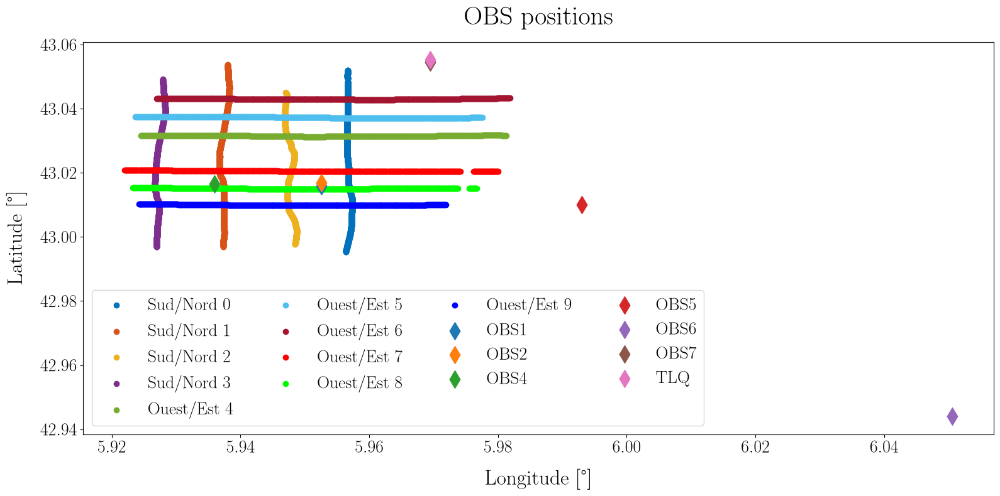

In [4]:
plot_portion_tir_pos(portion_tree=portion)

# Correction de la position des OBS

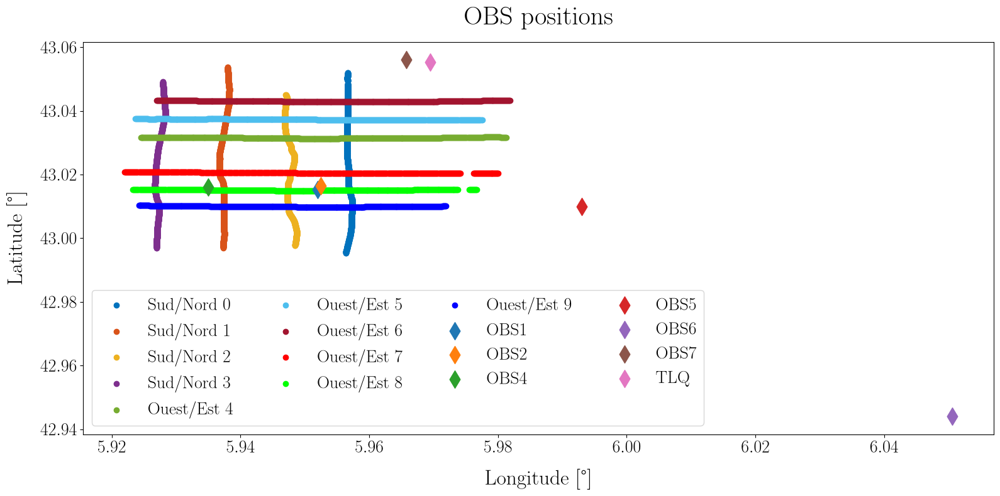

In [5]:
apply_obs_pos_correction = True 

if apply_obs_pos_correction:
    apply_rcv_position_correction_to_portion(portion_tree=portion)
    portion
    plot_portion_tir_pos(portion_tree=portion)

# Visualisation des données de pression

## Signaux

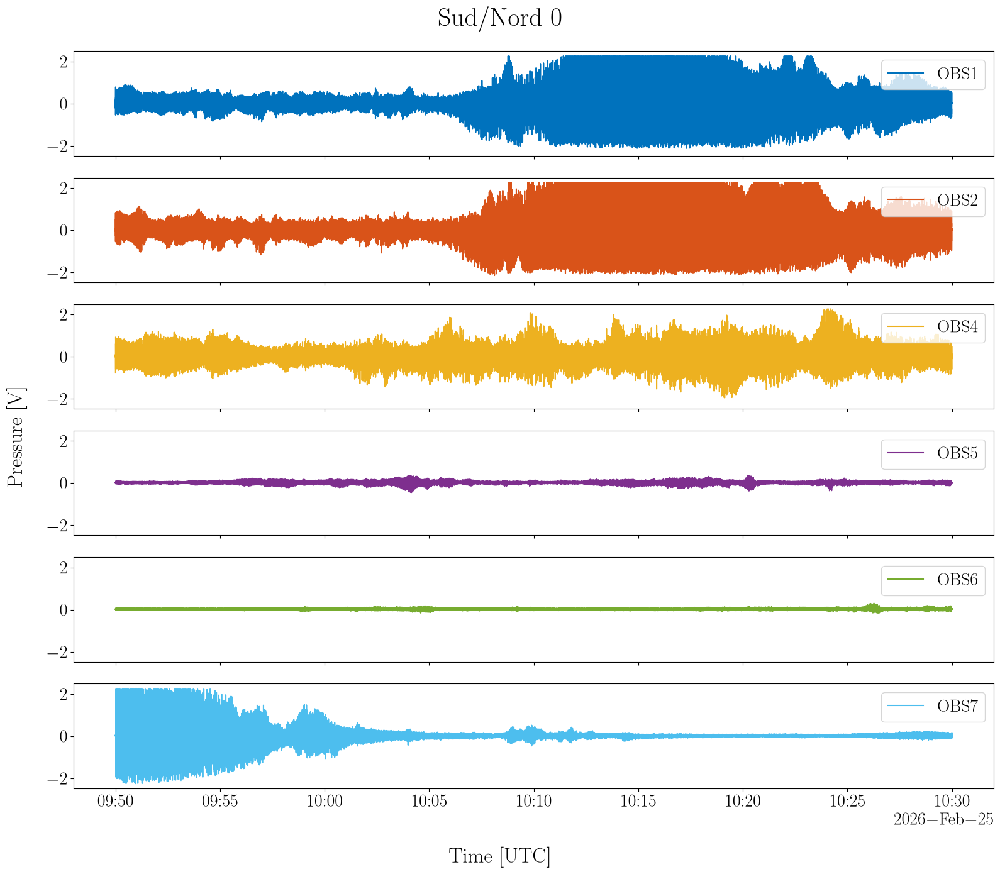

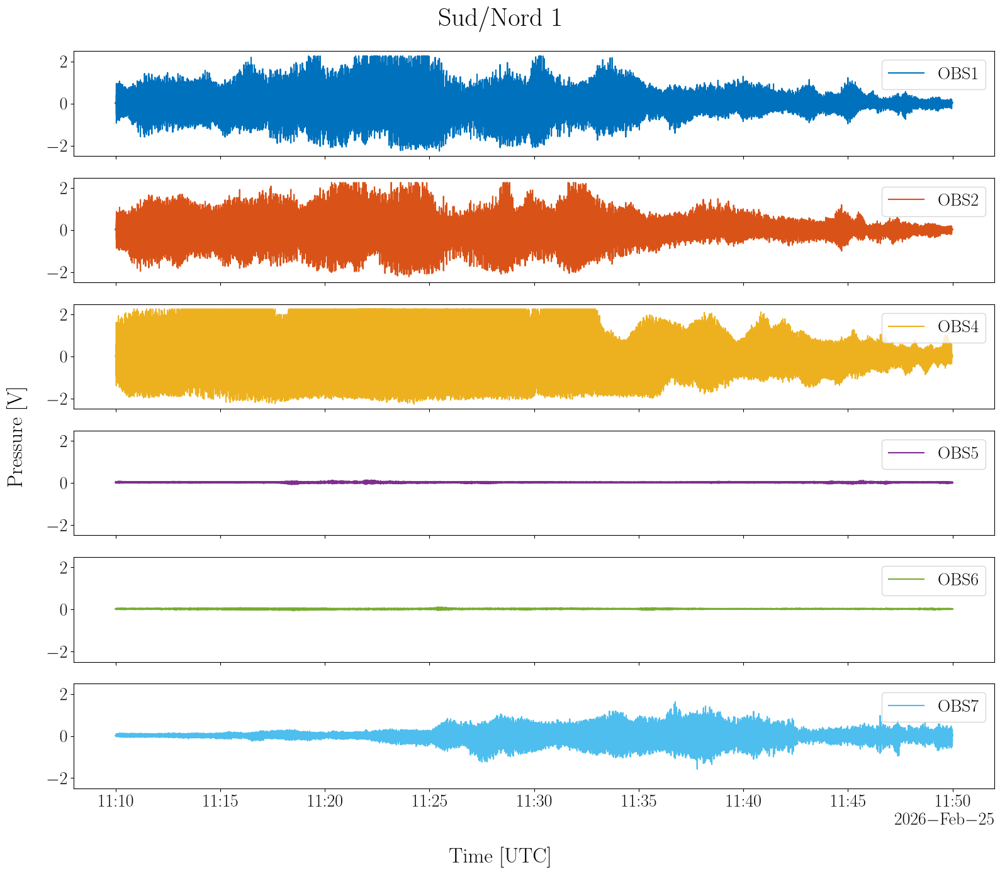

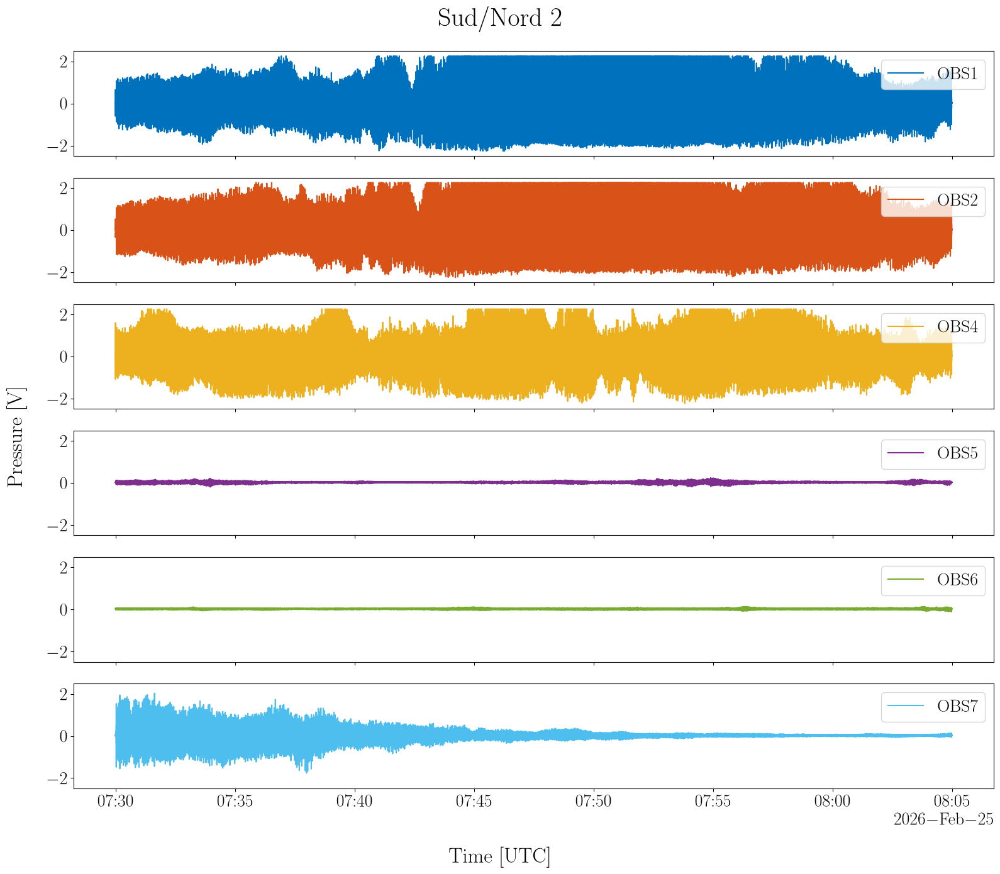

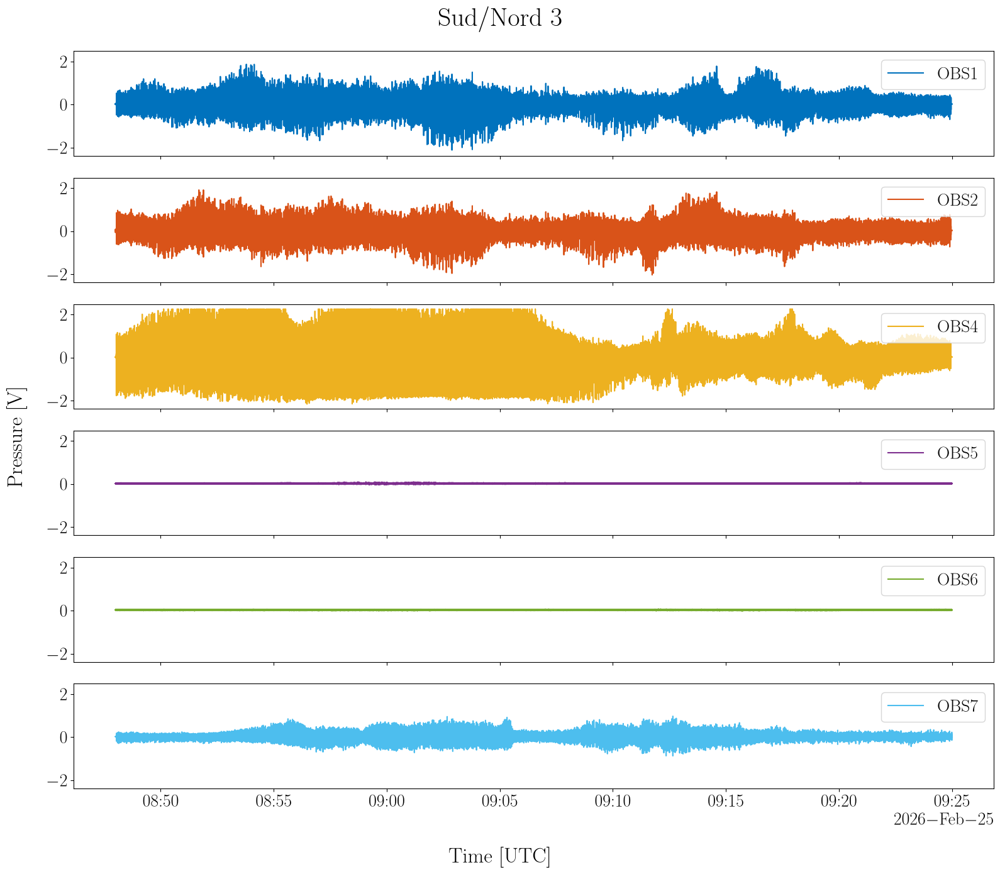

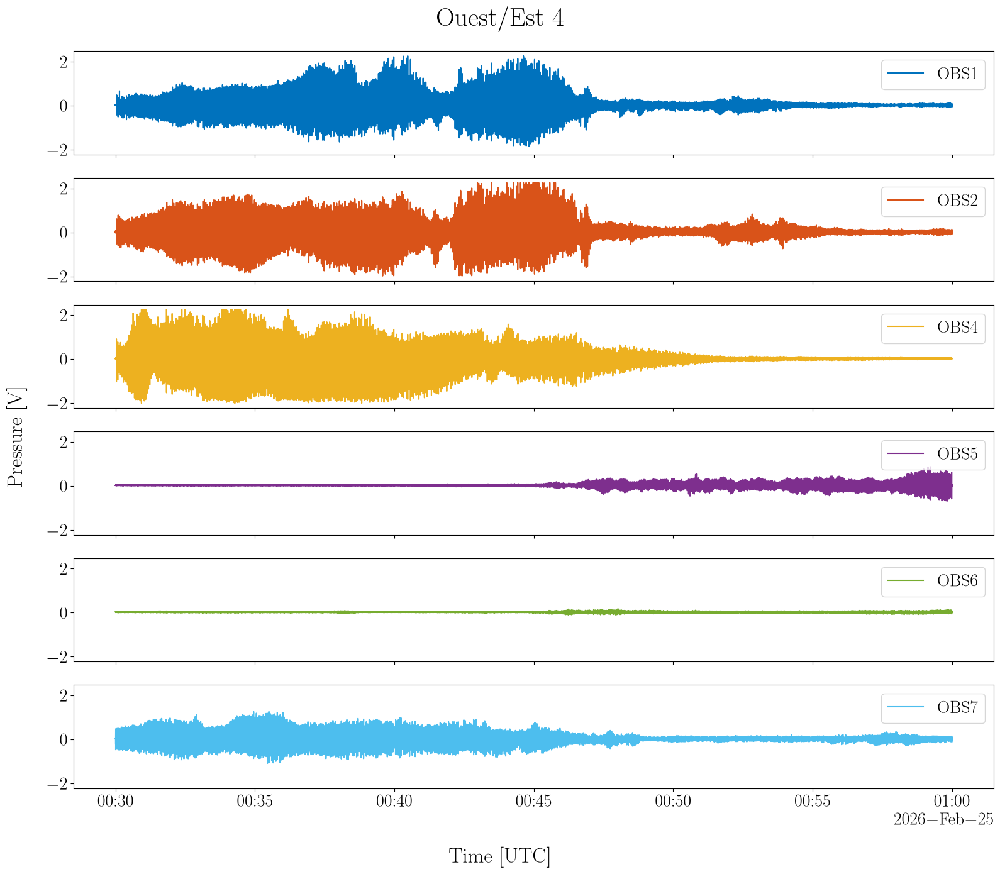

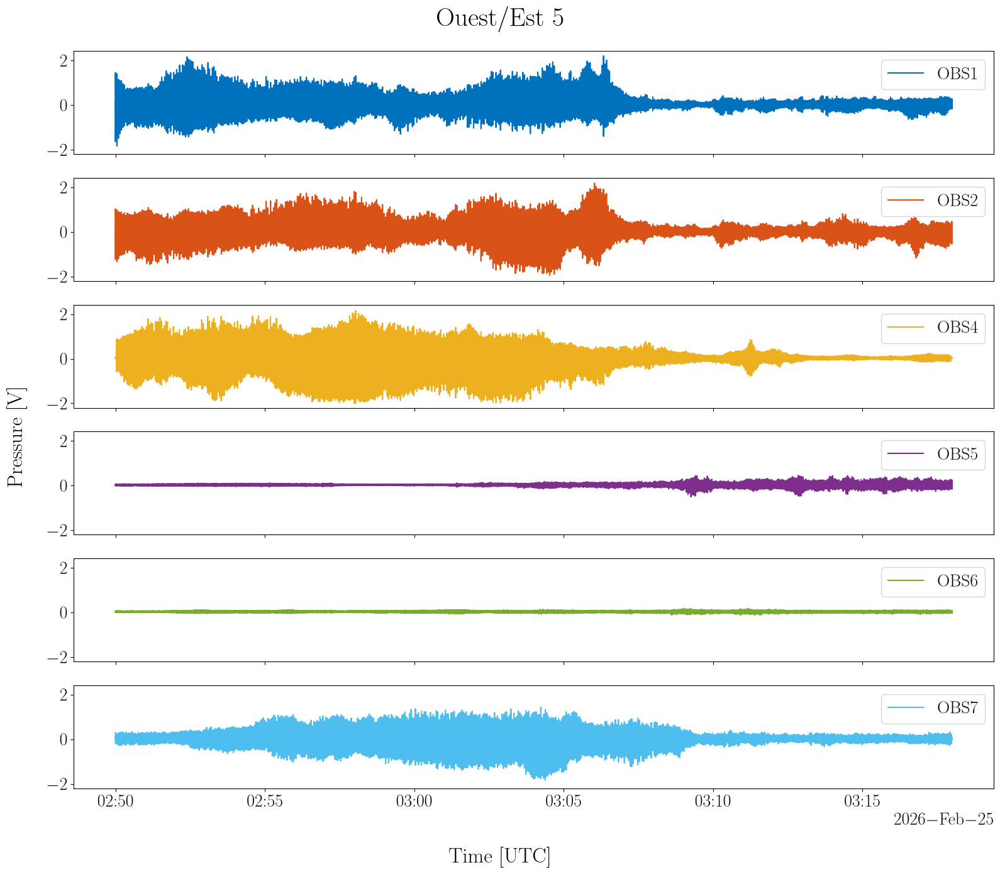

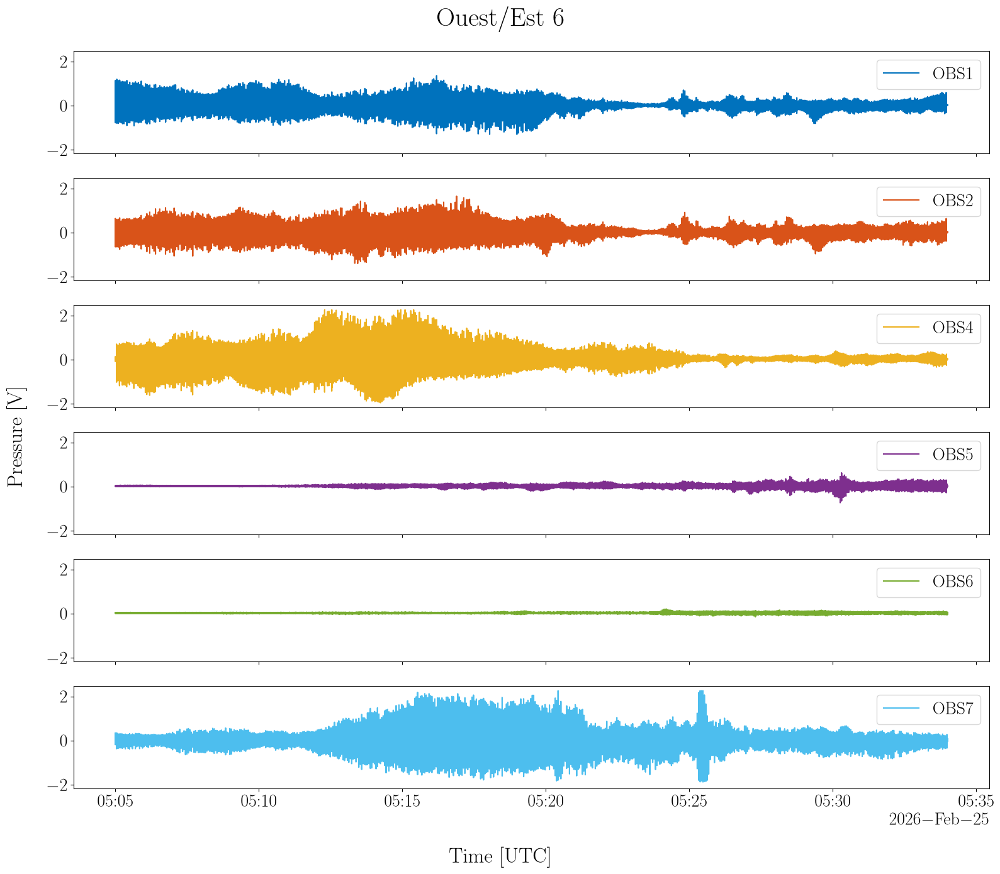

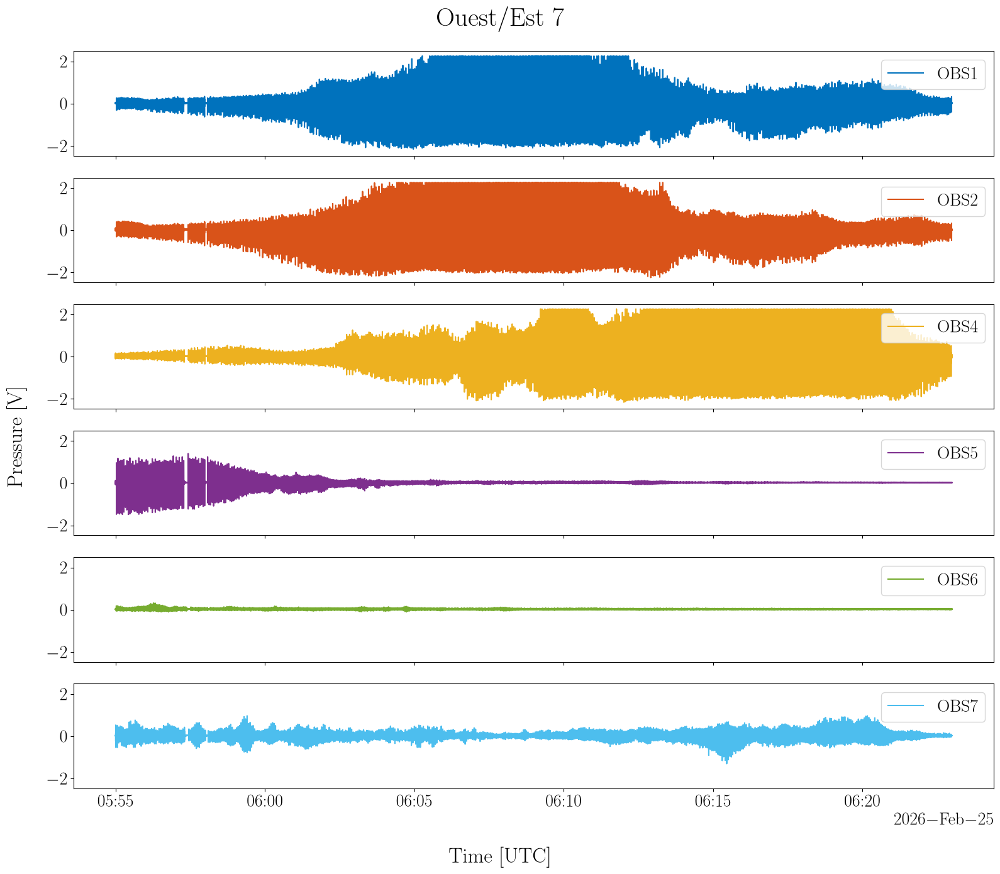

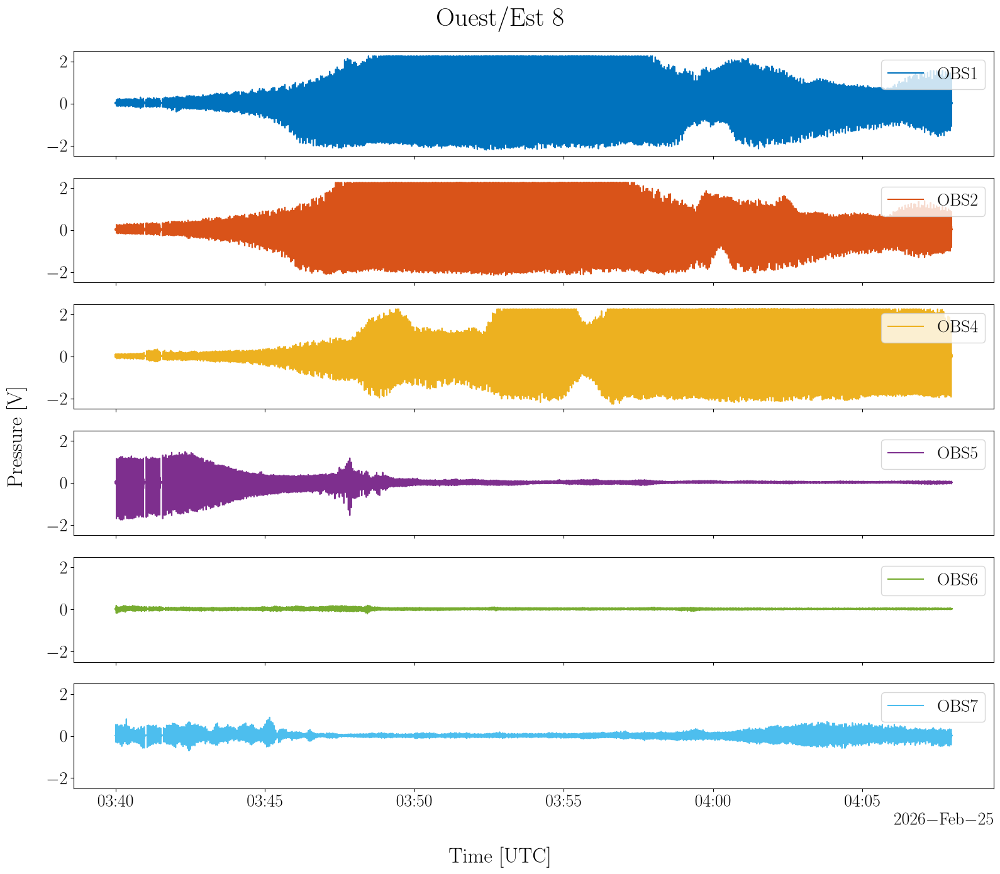

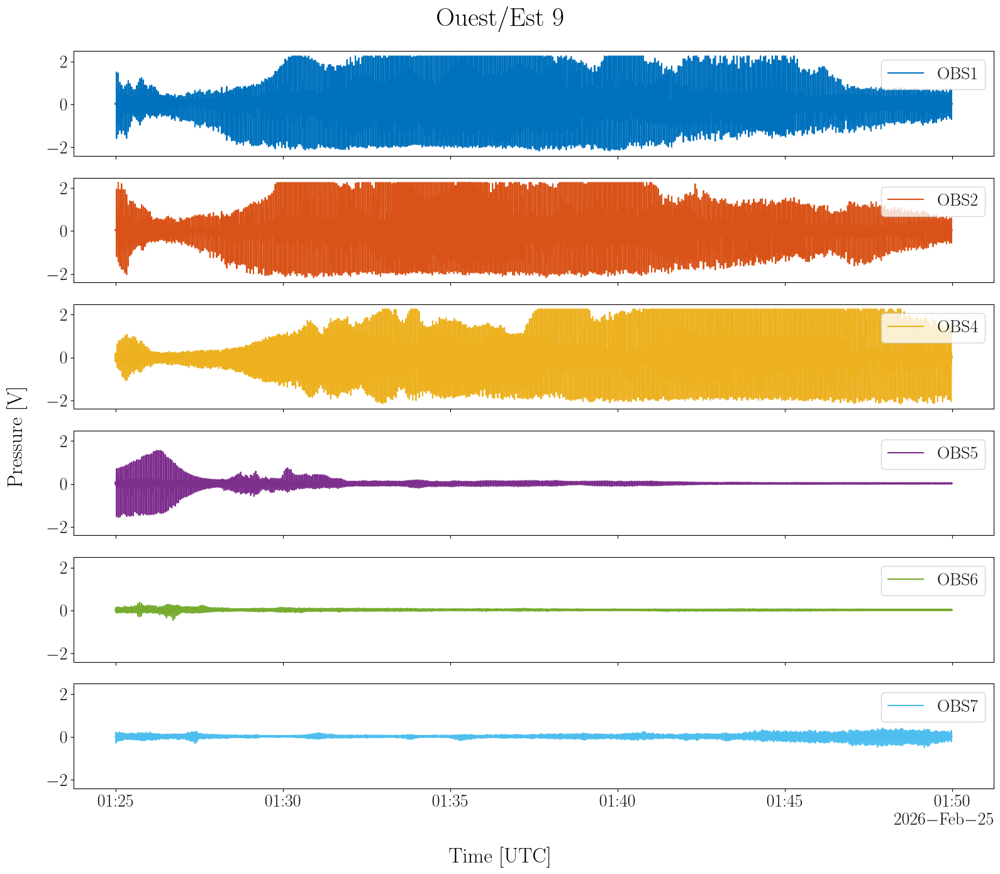

In [6]:
# Plot 
single_fig = False
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    fig, axs = plot_pressure_section(ds_pressure_section=ds_pressure_section, single_fig=single_fig)
    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    plt.show()

## Spectrogrames 

**Remarque** : l'amplitude des cannons décroit avec le temps avant de revenir à l'amplitude de départ. Ce comportement nominal des cannons à air comprimé se traduit par une modulation d'amplitude des tirs visibles sur les spectrogrames ci dessous.    

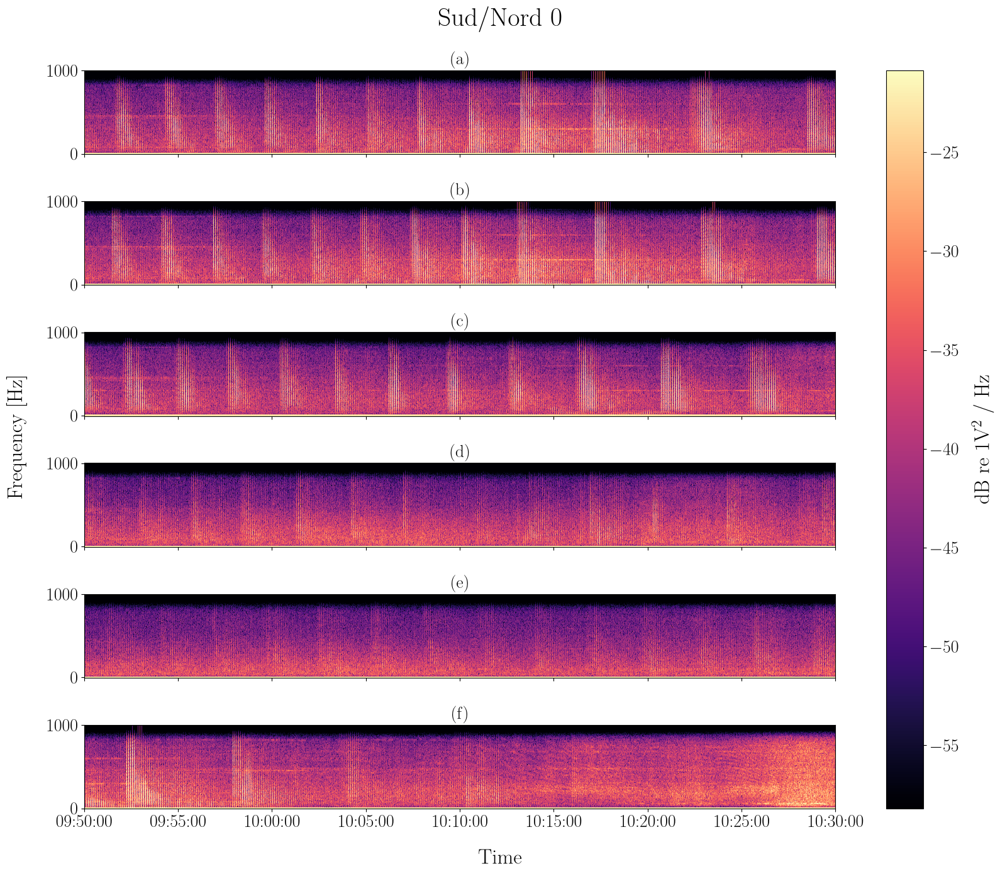

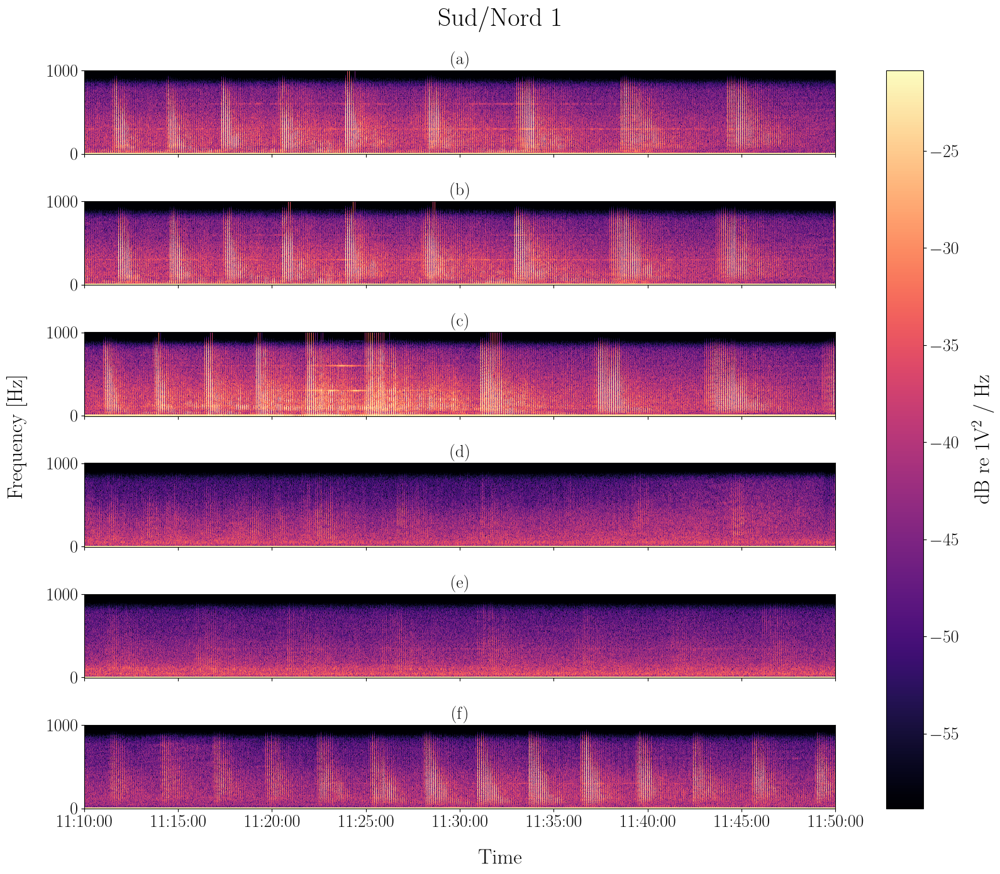

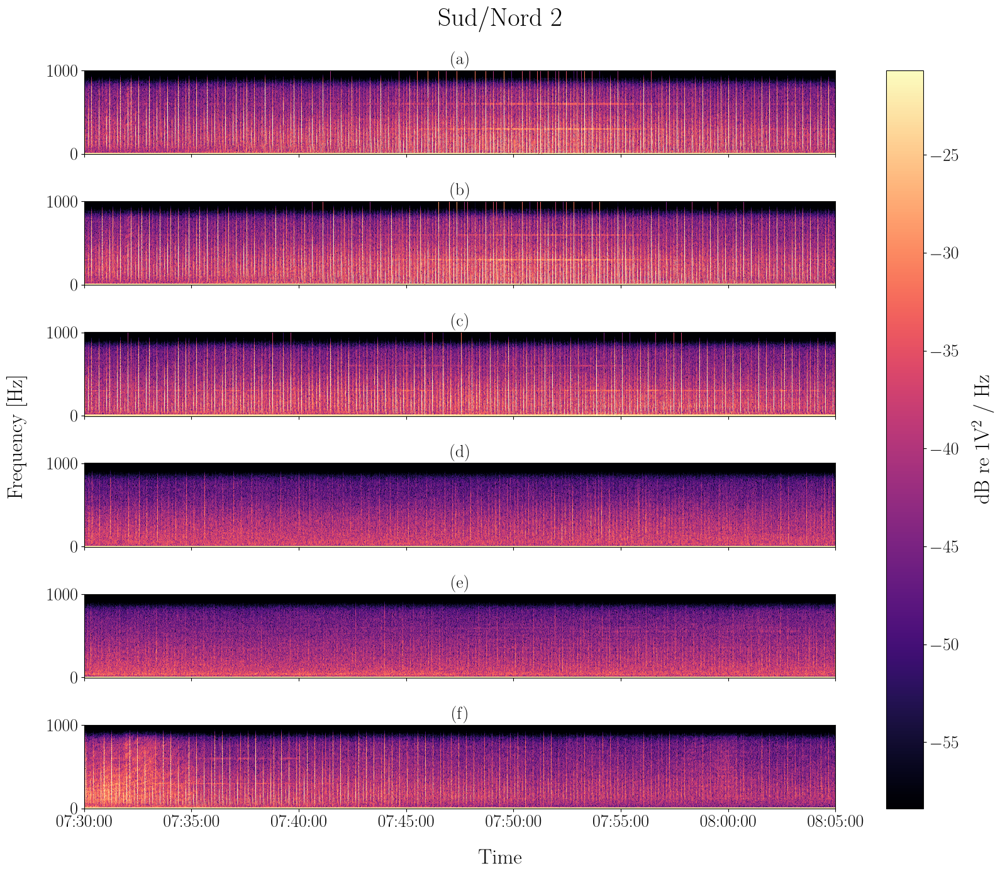

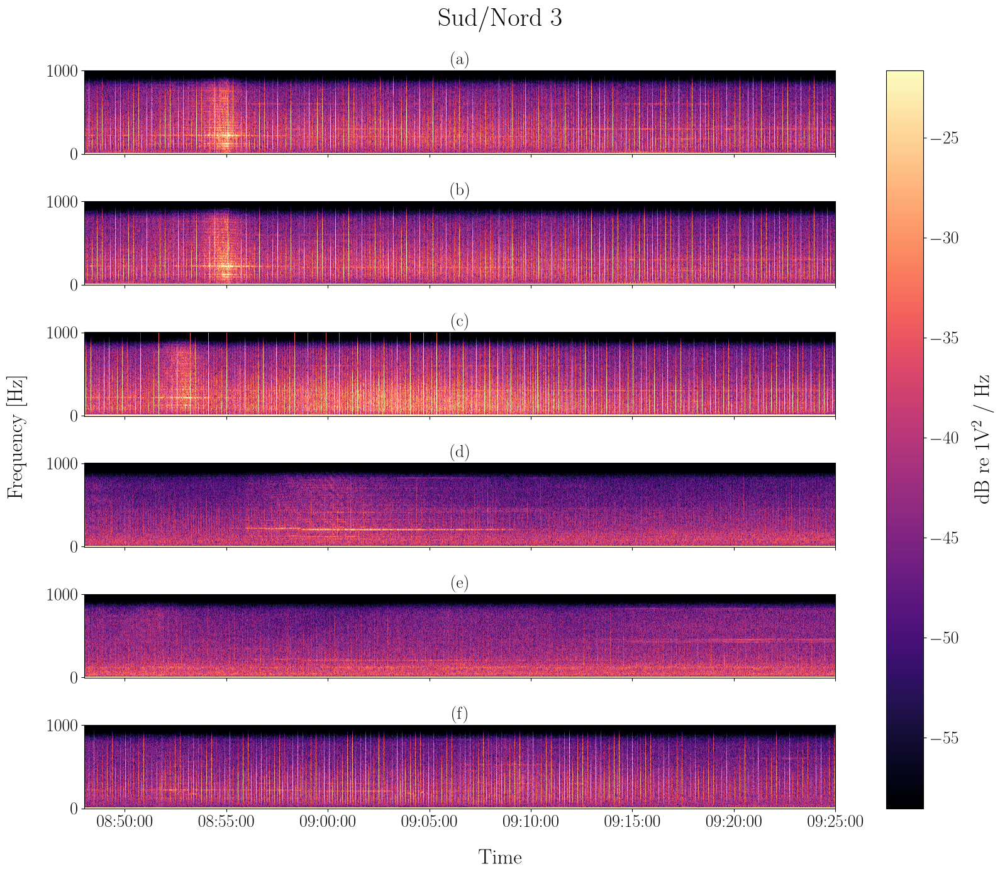

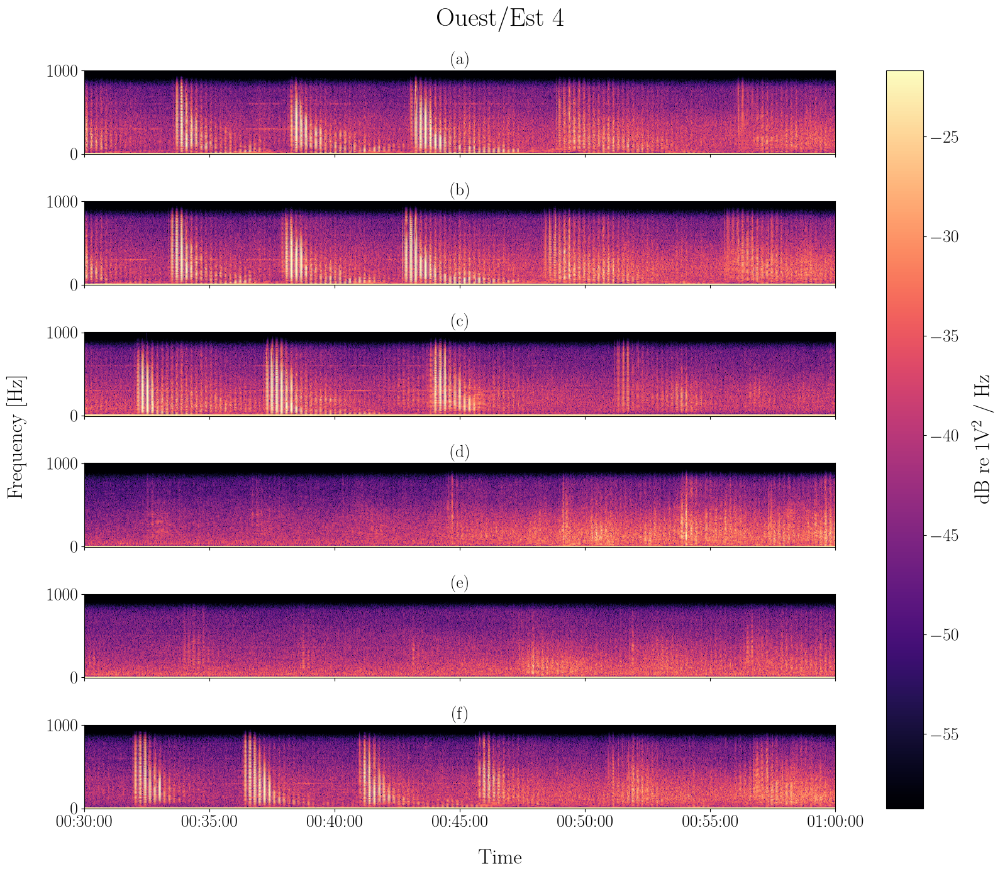

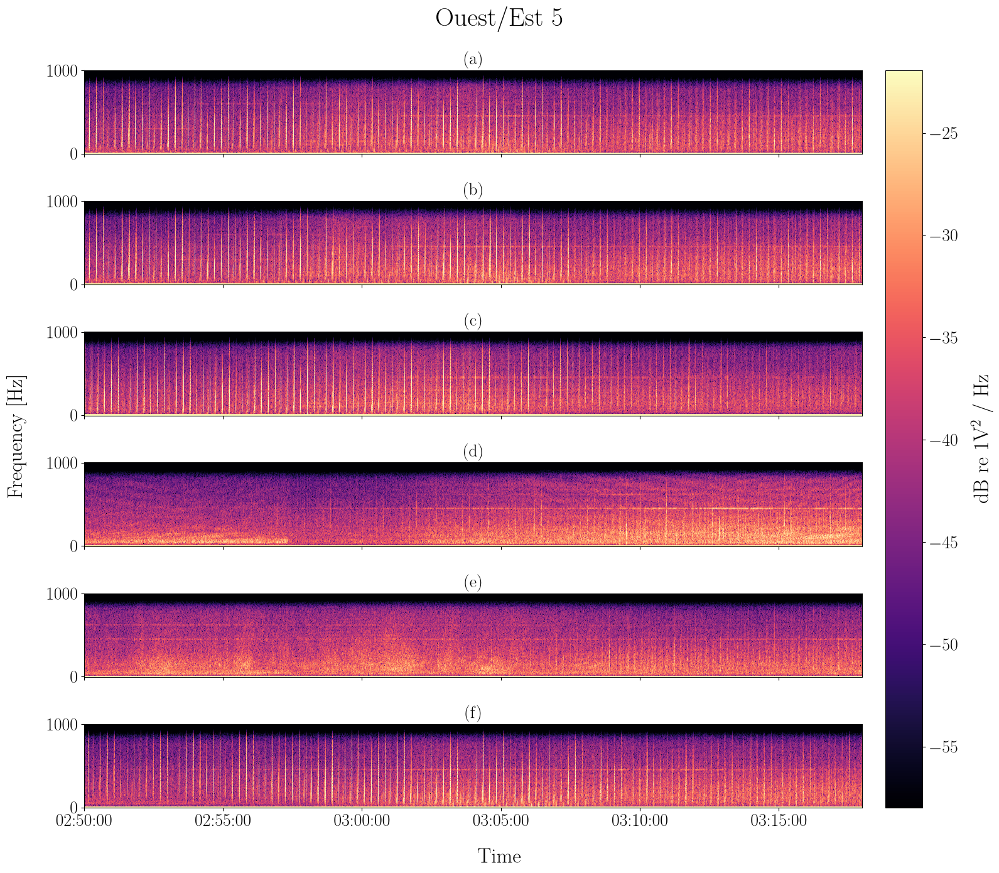

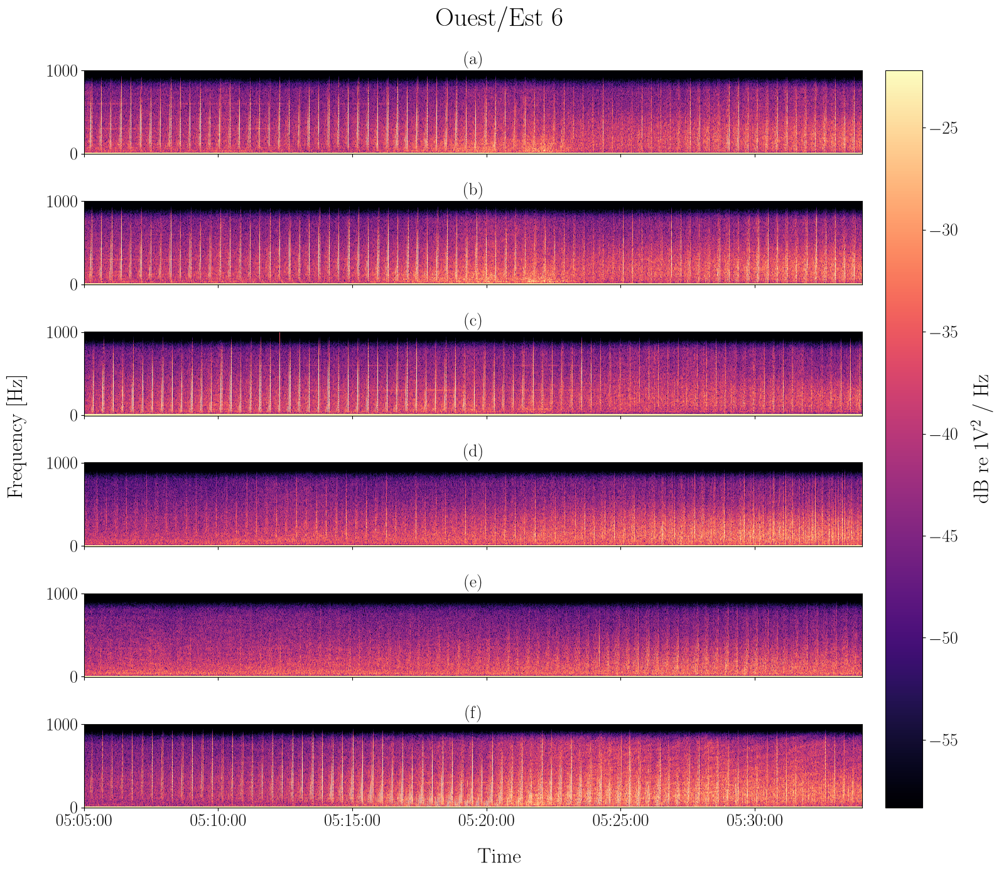

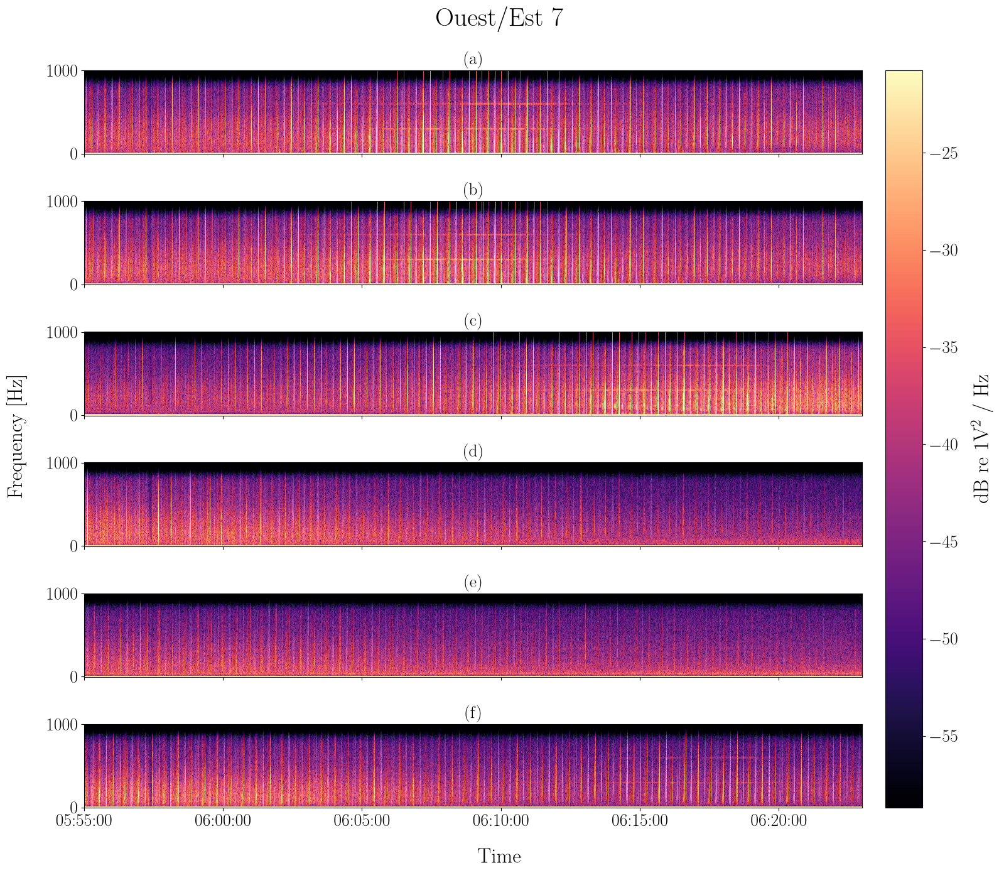

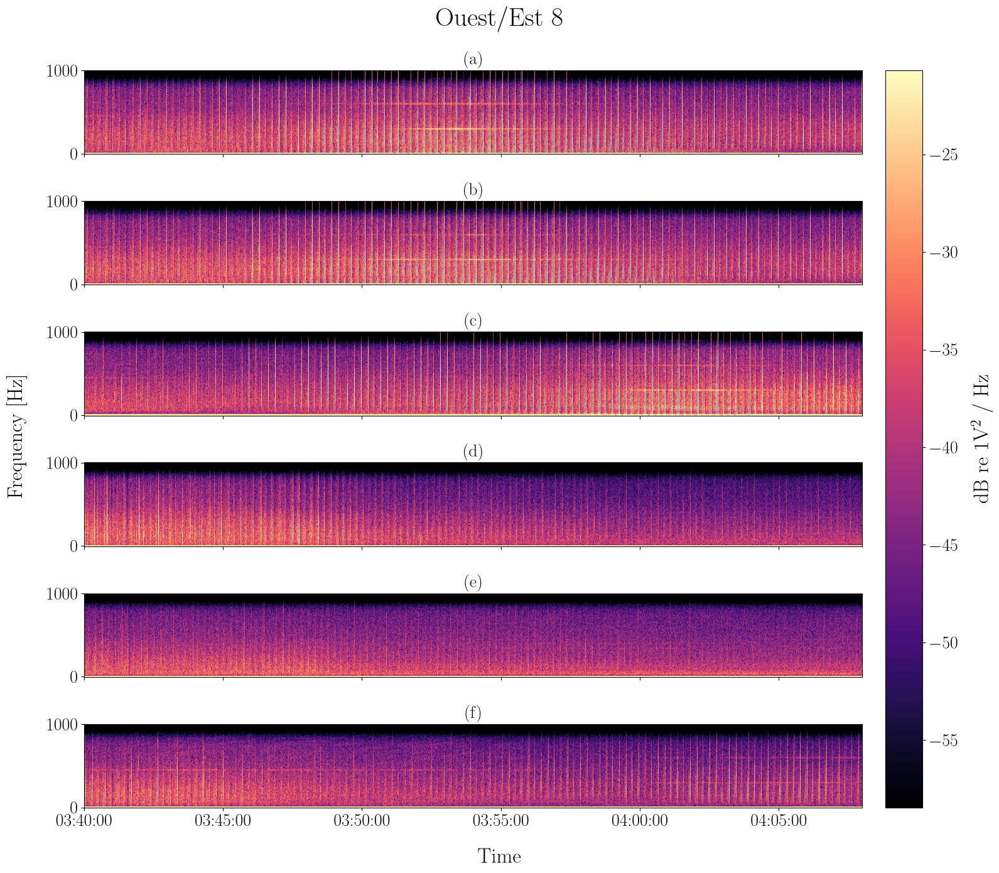

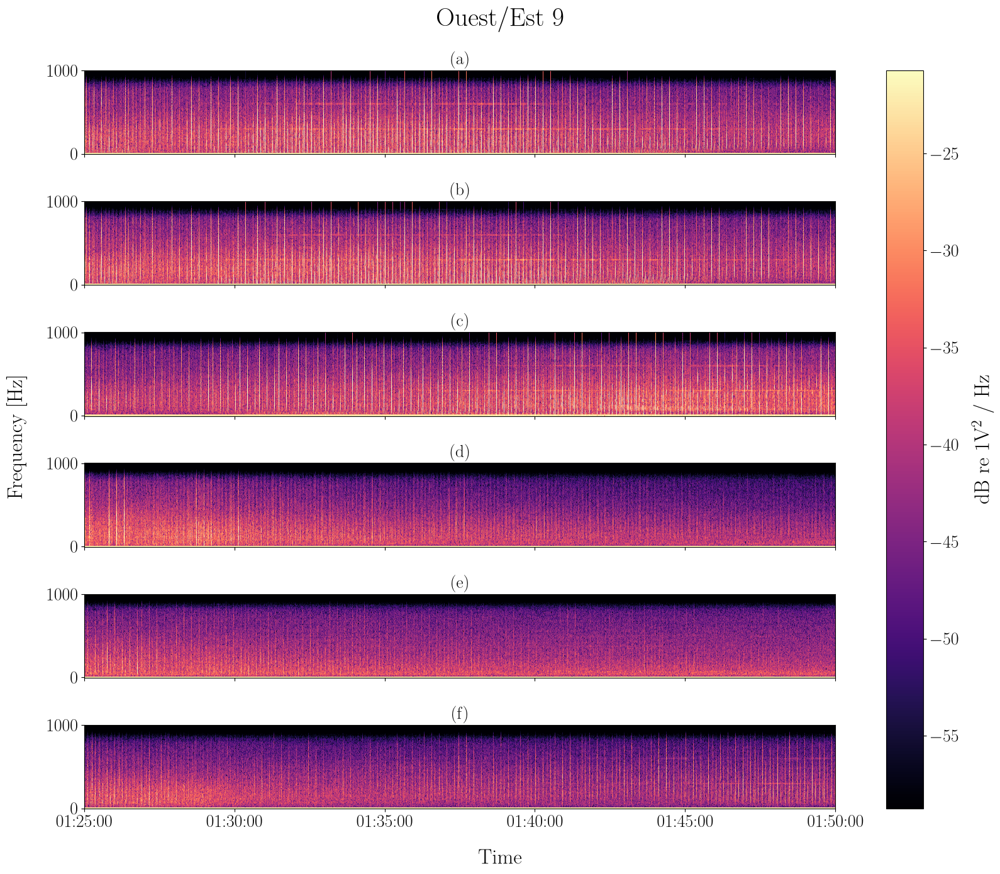

In [7]:
# Plot 
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    fig, axs = plot_spectrogram_section(ds_pressure_section, nperseg=2**8, noverlap=2**7, cmap="magma")
    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    plt.show()

# Calcul des grandeurs signantes 

In [8]:
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                   ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:5...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:50...
│   │         * src_datetime           (src_datetime) datetime64[ns] 6kB 2026-02-25T09:50...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B 5.952 5.953 5.935 ... 5.966 5.97
│   │           rcv_lat                (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 19kB ...
│   │           atl_lat                (atl_datetime) float64 19kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 1MB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 6kB ...
│   │           tir_src_lon            (src_datetime) float64 6kB 5.957 5.957 ... 5.956
│   │           tir_src_lat            (src_datetime) float64 6kB 43.05 43.05 ... 43.0 43.0
│   │           tir_vessel_lon         (src_datetime) float64 6kB ...
│   │           tir_vessel_lat         (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 44kB 4.11e+03 ... 6...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               4
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/sn2
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                   ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:1...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:10...
│   │         * src_datetime           (src_datetime) datetime64[ns] 6kB 2026-02-25T11:10...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B 5.952 5.953 5.935 ... 5.966 5.97
│   │           rcv_lat                (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 17kB ...
│   │           atl_lat                (atl_datetime) float64 17kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 1MB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 6kB ...
│   │           tir_src_lon            (src_datetime) float64 6kB 5.937 5.937 ... 5.938
│   │           tir_src_lat            (src_datetime) float64 6kB 43.0 43.0 ... 43.05 43.05
│   │           tir_vessel_lon         (src_datetime) float64 6kB ...
│   │           tir_vessel_lat         (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 45kB 2.354e+03 ... ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:      

## Extraction de chaques émissions

### Calcul de la célérité équivalente 

In [9]:
celerity = xr.open_datatree(ACOUPLANE_CELERITY_NC_FPATH)
celerity

<xarray.DataTree>
Group: /
├── Group: /T0_00006
│       Dimensions:      (depth: 322)
│       Coordinates:
│         * depth        (depth) float64 3kB 0.0 0.6301 1.26 1.89 ... 198.8 199.4 200.0
│       Data variables:
│           temperature  (depth) float64 3kB ...
│           celerity     (depth) float64 3kB ...
│       Attributes:
│           longitude:                 5.9519785
│           latitude:                  43.0480848
│           surface_temperatude_degC:  14.2
│           pression_atmo_hPa:         1021.0
│           salinity_ppt:              37.5
├── Group: /T0_00007
│       Dimensions:      (depth: 253)
│       Coordinates:
│         * depth        (depth) float64 2kB 0.0 0.6301 1.26 1.89 ... 156.2 156.8 157.4
│       Data variables:
│           temperature  (depth) float64 2kB ...
│           celerity     (depth) float64 2kB ...
│       Attributes:
│           longitude:                 5.9523738
│           latitude:                  43.0173035
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1020.2
│           salinity_ppt:              37.5
├── Group: /T0_00012
│       Dimensions:      (depth: 160)
│       Coordinates:
│         * depth        (depth) float64 1kB 0.0 0.6301 1.26 1.89 ... 98.39 99.02 99.64
│       Data variables:
│           temperature  (depth) float64 1kB ...
│           celerity     (depth) float64 1kB ...
│       Attributes:
│           longitude:                 5.9512852
│           latitude:                  43.0566788
│           surface_temperatude_degC:  14.7
│           pression_atmo_hPa:         1025.6
│           salinity_ppt:              37.5
├── Group: /T0_00020
│       Dimensions:      (depth: 233)
│       Coordinates:
│         * depth        (depth) float64 2kB 0.0 0.6301 1.26 1.89 ... 143.8 144.4 145.0
│       Data variables:
│           temperature  (depth) float64 2kB ...
│           celerity     (depth) float64 2kB ...
│       Attributes:
│           longitude:                 6.2931097
│           latitude:                  42.9943315
│           surface_temperatude_degC:  14.1
│           pression_atmo_hPa:         1027.3
│           salinity_ppt:              37.5
├── Group: /T0_00021
│       Dimensions:      (depth: 111)
│       Coordinates:
│         * depth        (depth) float64 888B 0.0 0.6301 1.26 1.89 ... 67.8 68.42 69.05
│       Data variables:
│           temperature  (depth) float64 888B ...
│           celerity     (depth) float64 888B ...
│       Attributes:
│           longitude:                 6.269442
│           latitude:                  43.0373697
│           surface_temperatude_degC:  14.7
│           pression_atmo_hPa:         1026.7
│           salinity_ppt:              37.5
├── Group: /T0_00022
│       Dimensions:      (depth: 144)
│       Coordinates:
│         * depth        (depth) float64 1kB 0.0 0.6301 1.26 1.89 ... 88.41 89.04 89.66
│       Data variables:
│           temperature  (depth) float64 1kB ...
│           celerity     (depth) float64 1kB ...
│       Attributes:
│           longitude:                 6.2833635
│           latitude:                  43.058786
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1026.9
│           salinity_ppt:              37.4
...
├── Group: /T7_00011
│       Dimensions:      (depth: 836)
│       Coordinates:
│         * depth        (depth) float64 7kB 0.0 0.6472 1.294 ... 524.1 524.7 525.4
│       Data variables:
│           temperature  (depth) float64 7kB ...
│           celerity     (depth) float64 7kB ...
│       Attributes:
│           longitude:                 5.9700047
│           latitude:                  43.0205393
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1023.7
│           salinity_ppt:              37.5
├── Group: /T7_00013
│       Dimensions:      (depth: 561)
│       Coordinates:
│         * depth        (depth) float64 4kB 0.0 0.6472 1.294 ... 354.4 355.0 355.7
│       

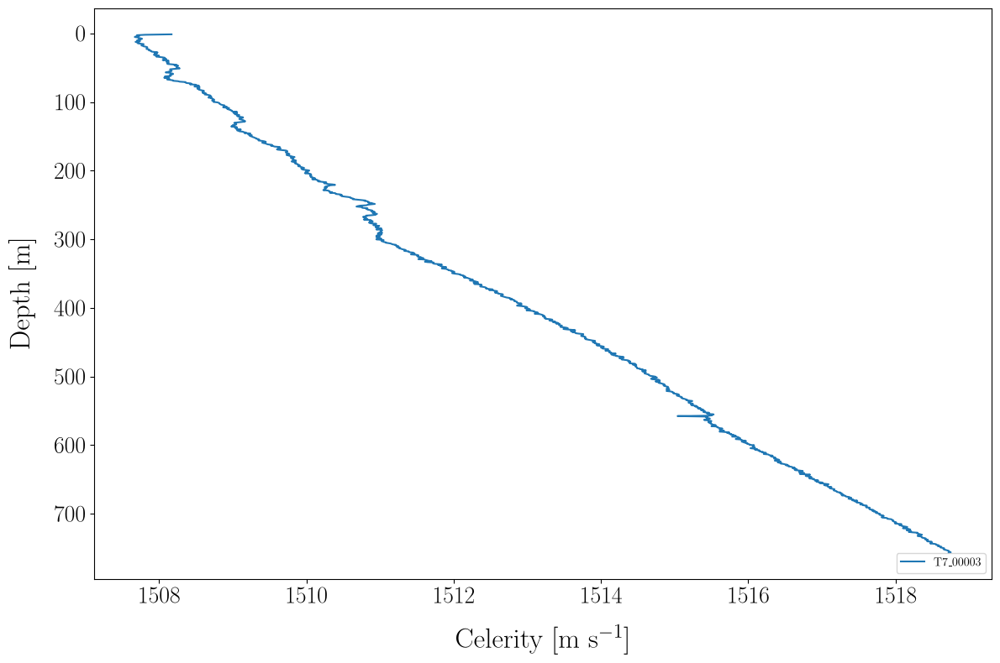

In [10]:
selected_profile = "T7_00003"
# selected_profile = "T0_00020"

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
for name, node in celerity.children.items():
    if name == selected_profile:
        ds = node.to_dataset()
        ds.celerity.plot(y="depth", ax=ax, yincrease=False, label=name)

    # ds = node.to_dataset()
    # ds.celerity.plot(y="depth", ax=ax, yincrease=False, label=name)


# for ax in axs.flatten():
ax.legend(loc="lower right", ncols=2, fontsize=10)
# axs[1].legend(loc="upper right", ncols=2, fontsize=10)
# axs[1].set_ylabel("")

# plt.ylim(500, 0)

In [11]:
ds_ = ds.sel(depth=slice(0, 100))
c_eq = equivalent_celerity(ds_.celerity.values, ds_.celerity.depth.values)
c_eq

np.float64(1508.1731018573482)

### Calcul des temps de propagation associés à chaque couple émission / récepteur 

In [12]:
c0 = c_eq
for name, node in portion.position.children.items():
    ds_pos_section = node.to_dataset()
    # Propagation distance assuming strait line propagation path
    dpropa_direct = np.sqrt(ds_pos_section.src_rcv_geodesic_dist**2 + ds_pos_section.rcv_immersion**2)
    # Compute propagation time 
    tps_propagation_s = dpropa_direct / c0 
    # tps_propagation_s = ds_pos_section.src_rcv_geodesic_dist / c0 
    ds_pos_section["tps_propagation_s"] = tps_propagation_s

    # Derive associated arrival dt 
    tps_propagation_ns = (tps_propagation_s * 1e9).round()
    tps_propagation_td = tps_propagation_ns.astype("timedelta64[ns]")
    ds_pos_section["tir_reception_datetime"] = tps_propagation_td + ds_pos_section.src_datetime

    # Update tree
    node.ds = ds_pos_section

In [13]:
ds_pos_section.tps_propagation_s

<xarray.DataArray 'tps_propagation_s' (rcv_id: 7, src_datetime: 500)> Size: 28kB
array([[1.14358976, 1.13850284, 1.13336859, ..., 1.54010995, 1.54504009,
        1.54998857],
       [1.15157356, 1.14665997, 1.14170219, ..., 1.58878577, 1.59364989,
        1.59853627],
       [2.0457002 , 2.04040699, 2.03506196, ..., 0.7217296 , 0.72578258,
        0.72989178],
       ...,
       [6.46375774, 6.46724408, 6.47076882, ..., 8.39137693, 8.39551344,
        8.39960826],
       [3.40785125, 3.40747217, 3.40709672, ..., 4.05216854, 4.05497675,
        4.0578507 ],
       [3.33690793, 3.33684446, 3.33678796, ..., 4.11923817, 4.12224648,
        4.12531814]], shape=(7, 500))
Coordinates:
  * rcv_id        (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs6' 'obs7' 'tlq'
  * src_datetime  (src_datetime) datetime64[ns] 4kB 2026-02-25T01:25:00.60009...
Attributes:
    units:      m
    long_name:  Immersion below MSL

In [14]:
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB 43.05 43.05 ... 43.0 43.0
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB 4.11e+03 ... ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB 2.726 ... 4.475
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               4
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/sn2
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 17kB ...
│   │           atl_lat                 (atl_datetime) float64 17kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB 43.0 43.0 ... 43.05 43.05
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 45kB 2.354e+03 ......
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 45kB 1.563 ... 1.705
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 45kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │          

In [15]:
(portion.position.sn1.rcv_immersion, portion.position.sn1.rcv_id)

(<xarray.DataArray 'rcv_immersion' (rcv_id: 7)> Size: 14B
 array([ 119,  116,  118, 1077,  306,   93,   93], dtype=int16)
 Coordinates:
   * rcv_id   (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7' 'tlq'
 Attributes:
     units:      m
     long_name:  Immersion below MSL,
 <xarray.DataArray 'rcv_id' (rcv_id: 7)> Size: 112B
 array(['obs1', 'obs2', 'obs4', 'obs5', 'obs6', 'obs7', 'tlq'], dtype='<U4')
 Coordinates:
   * rcv_id   (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7' 'tlq')

### Comparaison aux signaux 

In [16]:
# r = ds_pos_section.src_rcv_geodesic_dist.max()
# delta_c = 10
# delta_t = (r*delta_c) / c0**2
# delta_t

c0 = 1508
delta_r = 200
delta_t = 1 / c0 * delta_r
delta_t


0.1326259946949602

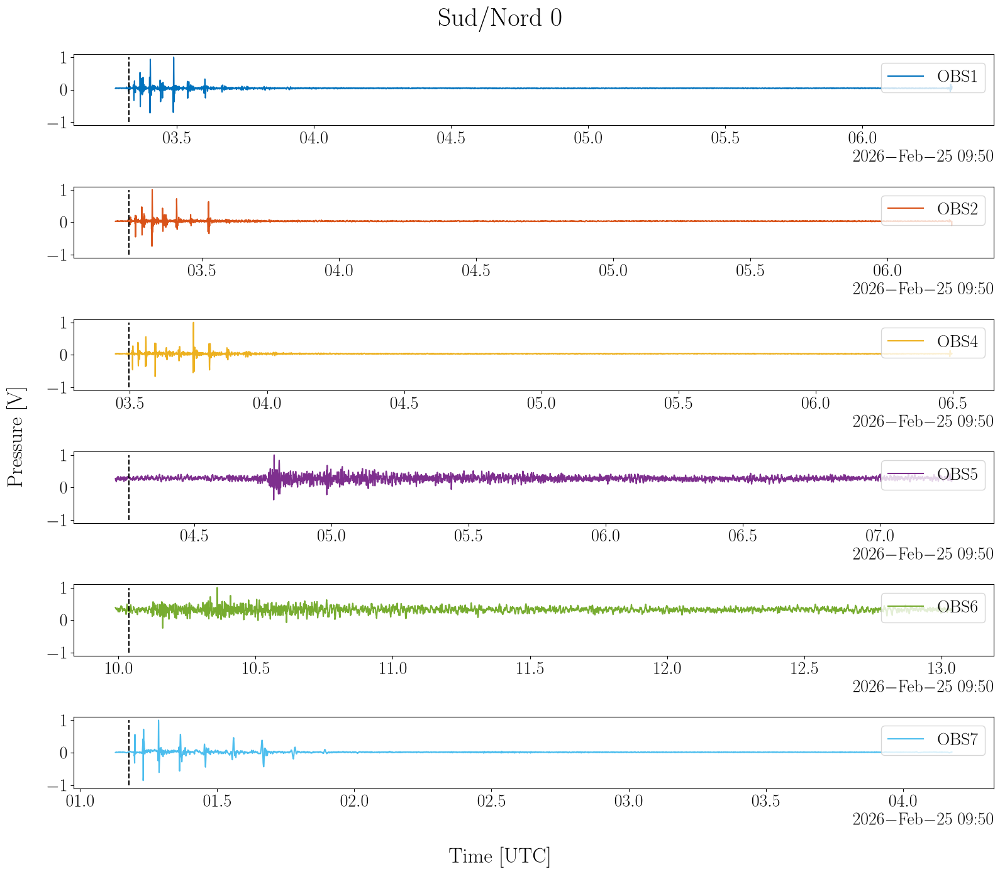

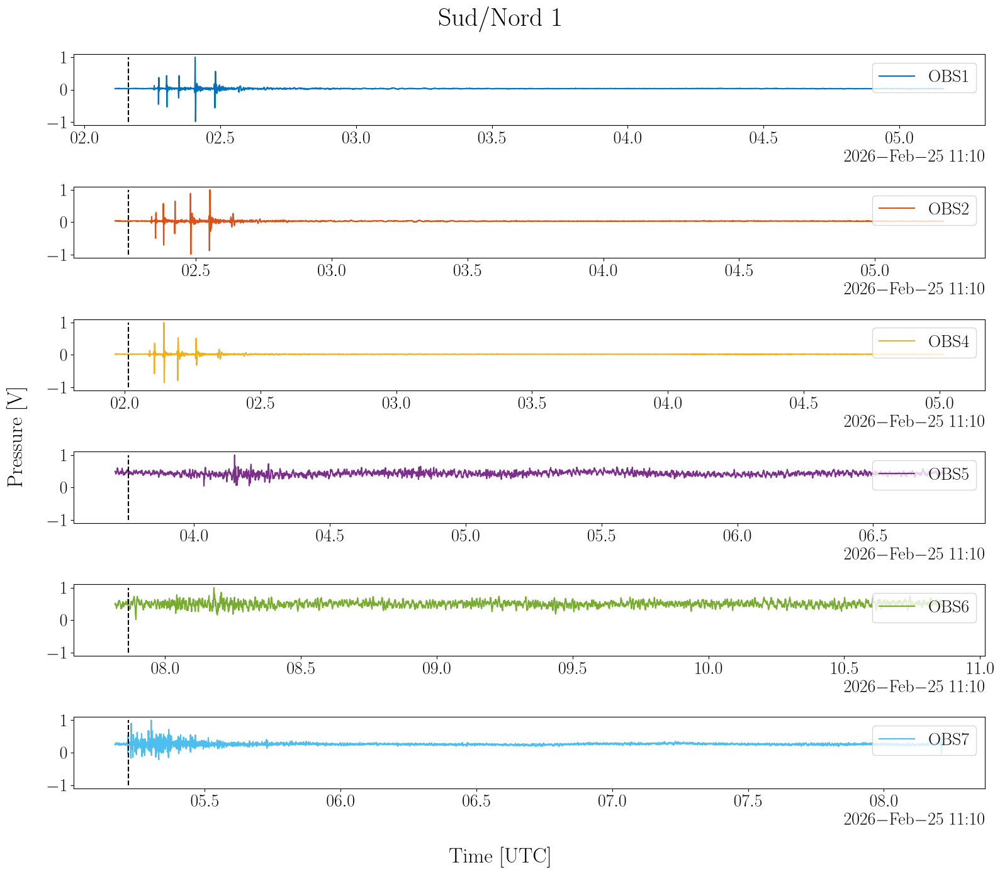

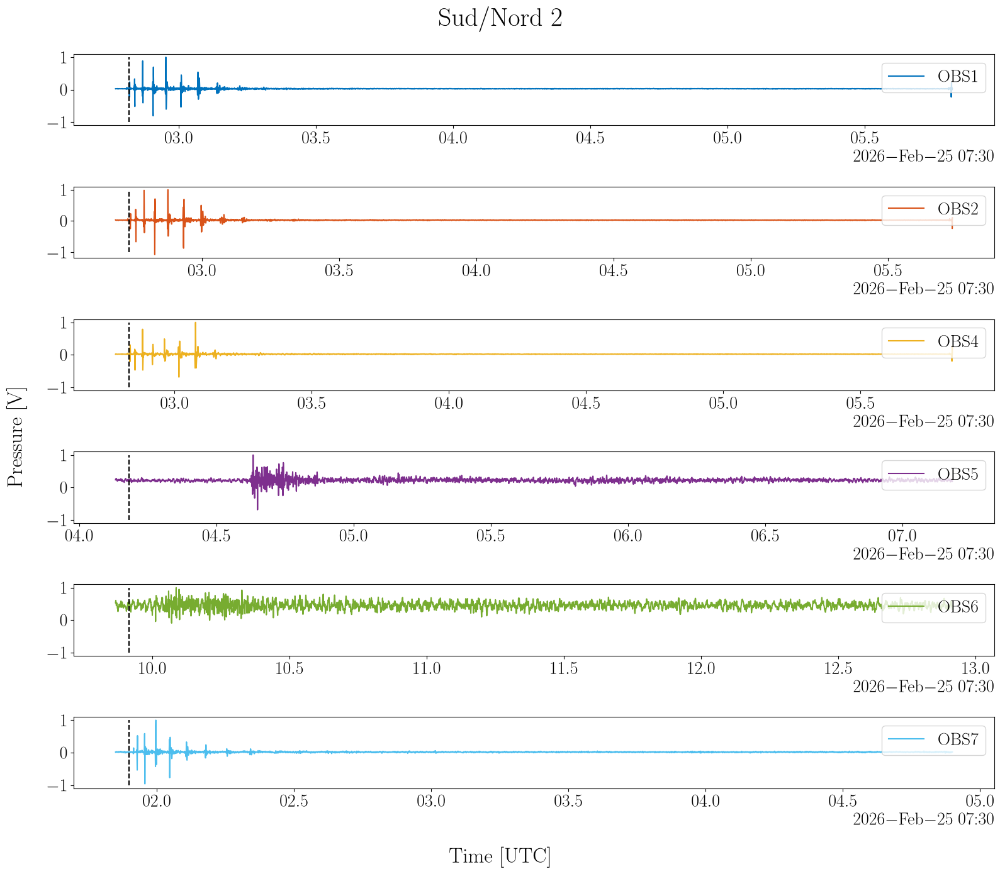

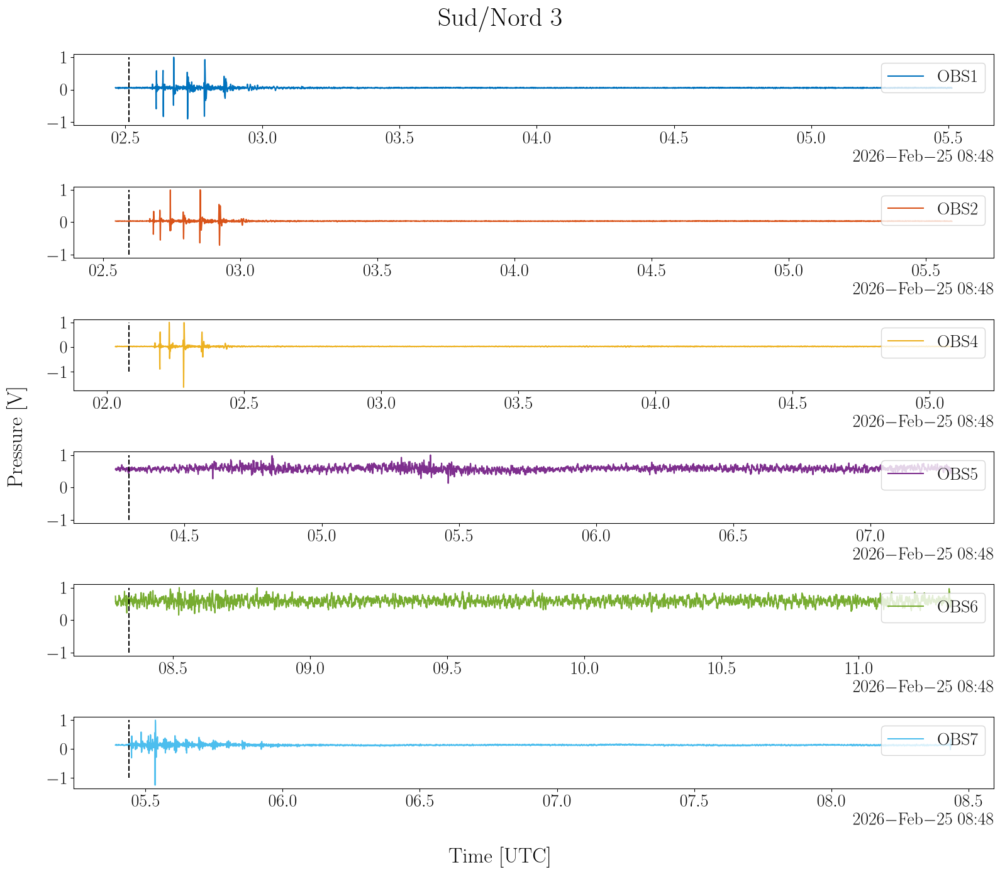

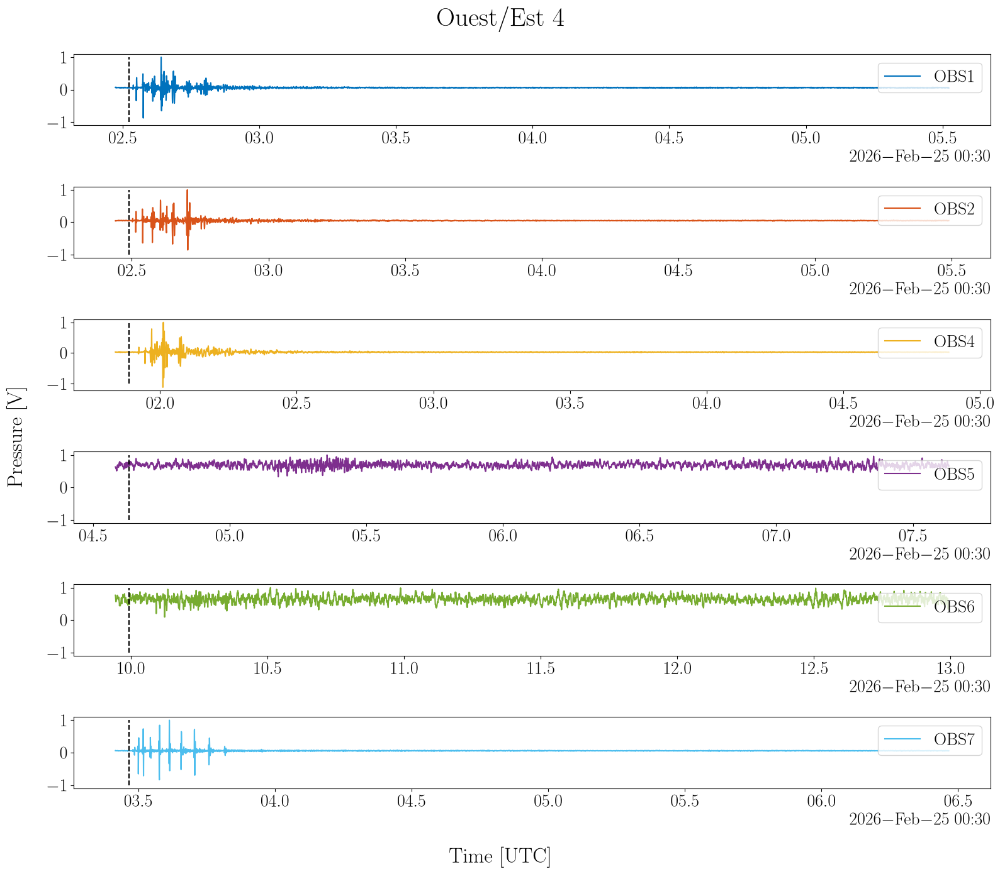

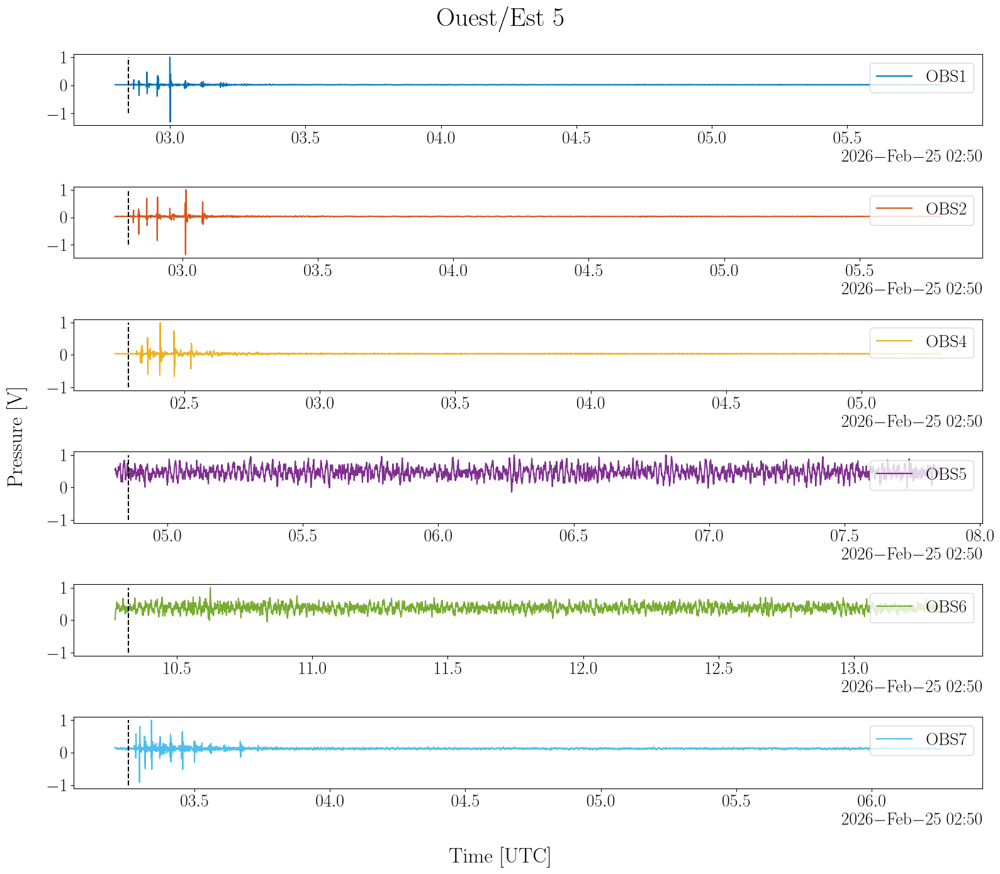

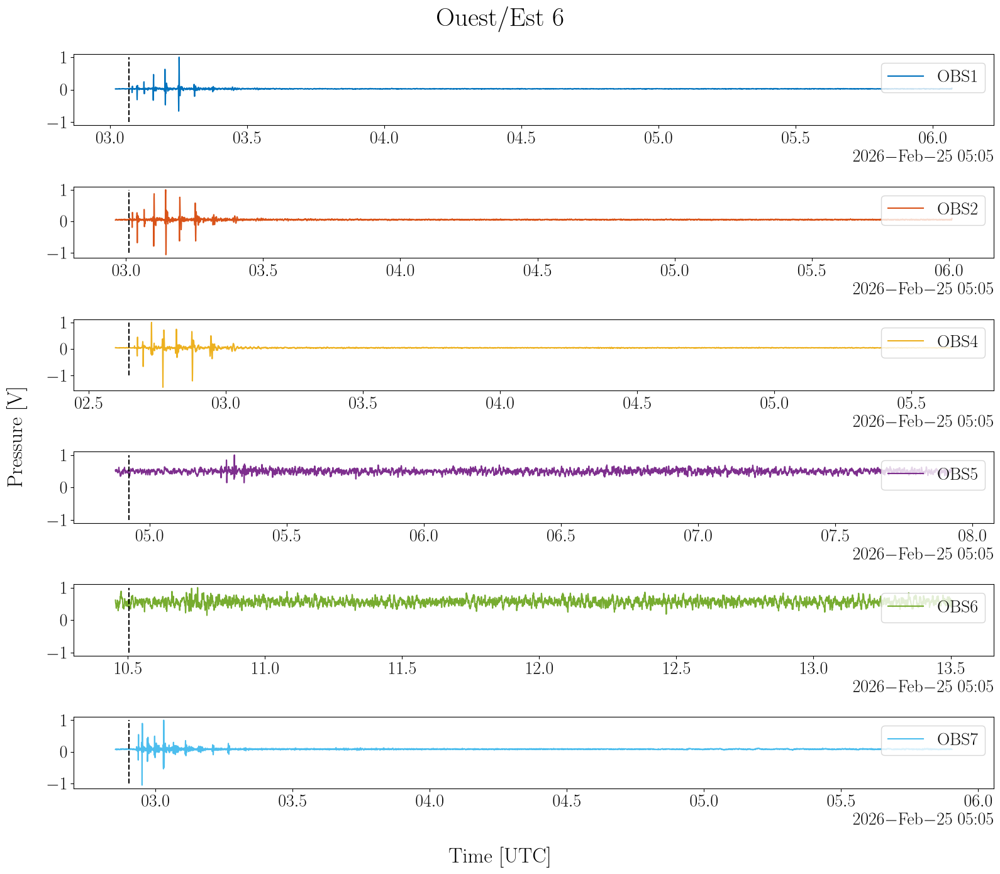

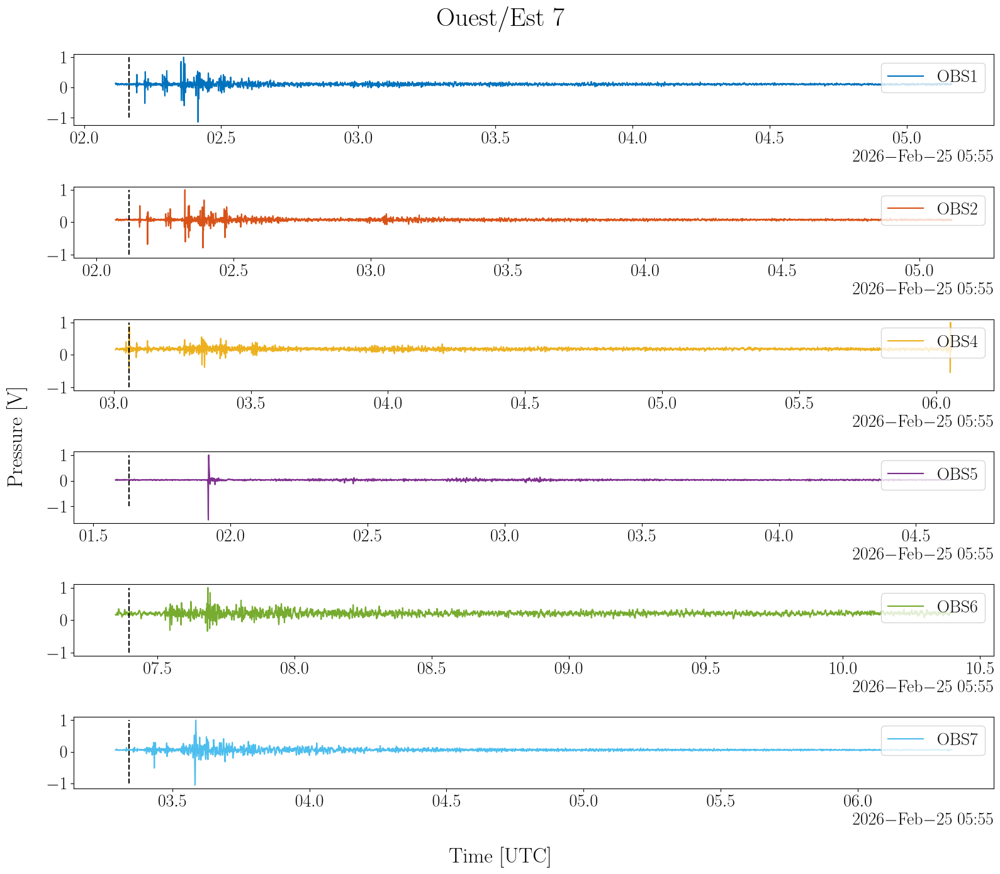

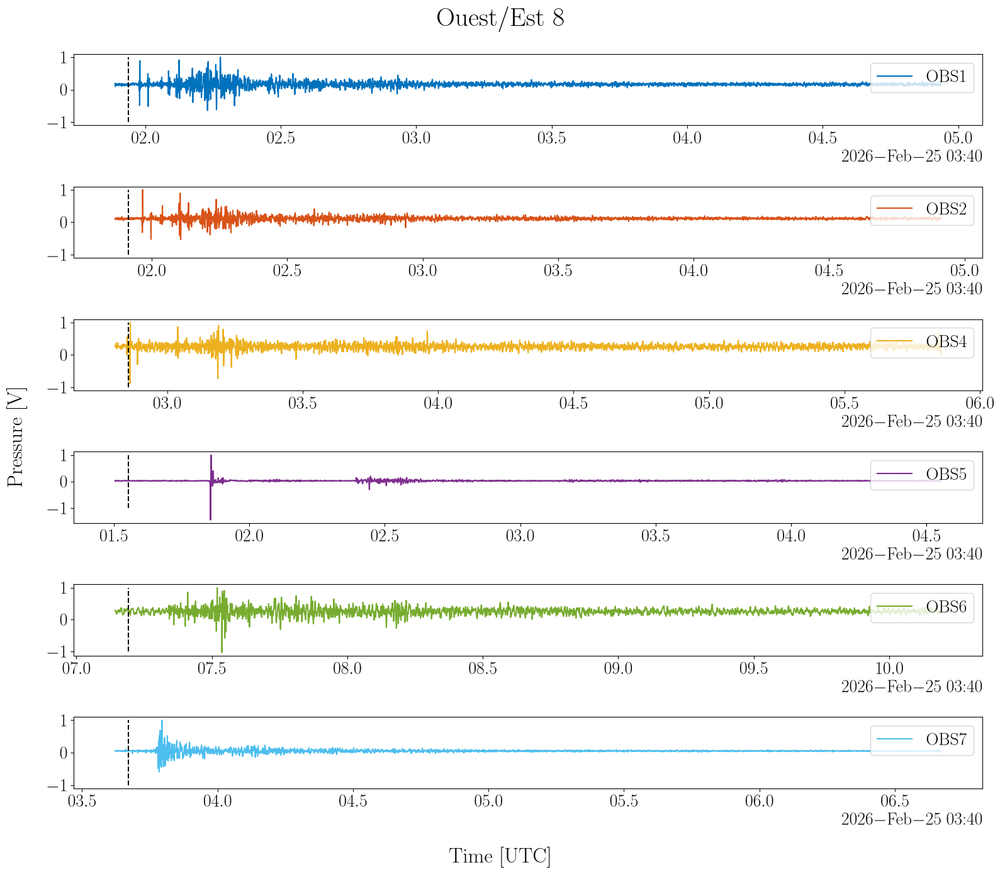

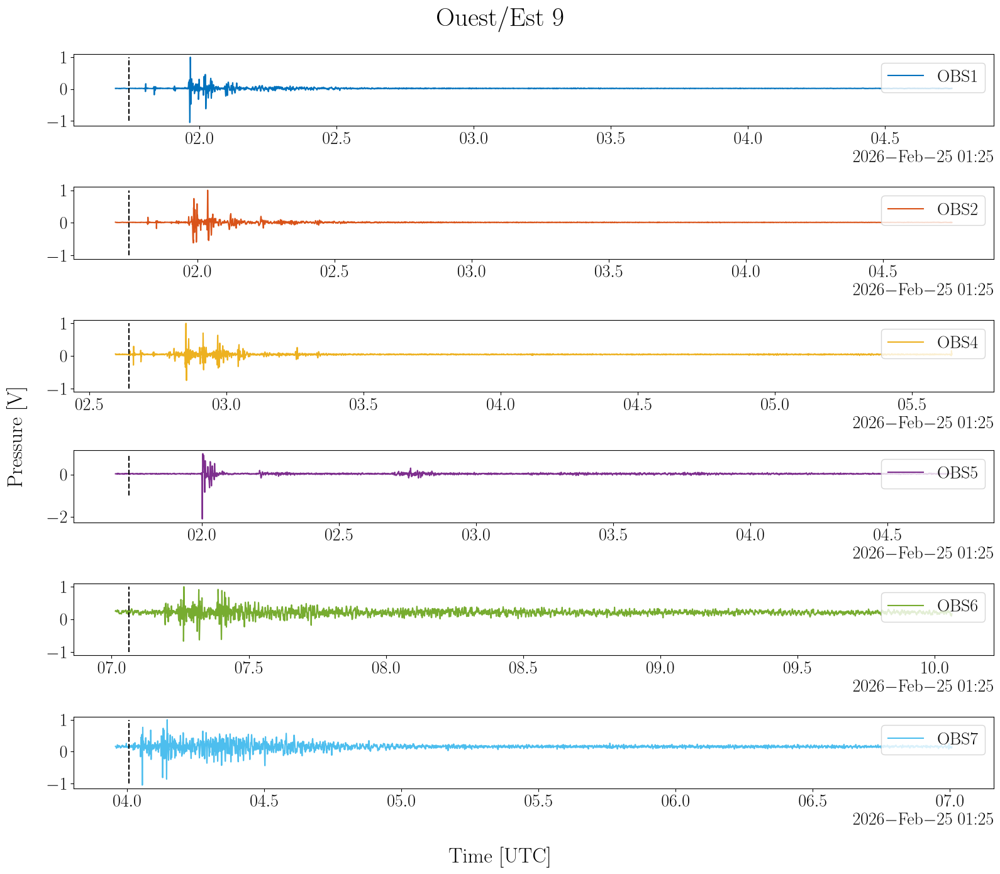

In [ ]:
nb_tir = 1
offset1 = 50
offset2 = 3000

obs_ids = list(portion.pressure.children.items())[0][1].to_dataset().obs_id.values
# obs_ids = obs_ids[[0, 3, 5]]
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()  
    # Associated ds_pos
    ds_pos_section = portion.position[name].to_dataset()
    tir_dt = ds_pos_section["tir_reception_datetime"].isel(src_datetime=slice(0, 0+nb_tir))

    fig, axs = plt.subplots(nrows=obs_ids.size, ncols=1, figsize=(16, 14), sharex=False)        
    axs = axs.flatten()
    for i, rcv_id in enumerate(obs_ids):
        tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
        # Select associated data window 
        press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel({f"time_{rcv_id}":slice(tir_dt_rcv.values[0]-np.timedelta64(offset1, 'ms'), tir_dt_rcv.values[-1]+np.timedelta64(offset2-offset1, 'ms'))})
        # Plot pressure signal 
        # Normalize 
        press_rcv = press_rcv / press_rcv.max()
        press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
        # Plot arrivals time 
        axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--")
        # Add legend
        axs[i].legend(loc="upper right")

    xlab = axs[0].get_xlabel()
    ylab = axs[0].get_ylabel()

    for ax in axs:
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title("")

    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    fig.supxlabel(xlab)
    fig.supylabel(ylab)

    plt.show()

# Calcul des grandeurs signantes 

In [18]:
derive_portion_cpsd(
    portion_tree=portion, offset_ms=100, signal_duration_s=3, nfft=2**15, obs_ids=None
)
portion

/home/program/ubf_tools/real_data_analysis/acouplane/src/acouplane_utils.py:1076: RuntimeWarning: invalid value encountered in multiply
  Sxy_arr = np.empty(shape=(nr, nr, nf), dtype=np.complex64) * np.nan
/home/program/ubf_tools/real_data_analysis/acouplane/src/acouplane_utils.py:1049: RuntimeWarning: Mean of empty slice
  signal_i = signal_i - np.nanmean(signal_i)


<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB 43.05 43.05 ... 43.0 43.0
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB 4.11e+03 ... ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB 2.726 ... 4.475
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               4
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/sn2
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 17kB ...
│   │           atl_lat                 (atl_datetime) float64 17kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB 43.0 43.0 ... 43.05 43.05
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 45kB 2.354e+03 ......
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 45kB 1.563 ... 1.705
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 45kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │          

/tmp/ipykernel_2709012/3625969037.py:28: RuntimeWarning: divide by zero encountered in divide
  dcf_ij = sij.values / np.sqrt(sii.values * sjj.values)
/tmp/ipykernel_2709012/3625969037.py:28: RuntimeWarning: invalid value encountered in divide
  dcf_ij = sij.values / np.sqrt(sii.values * sjj.values)


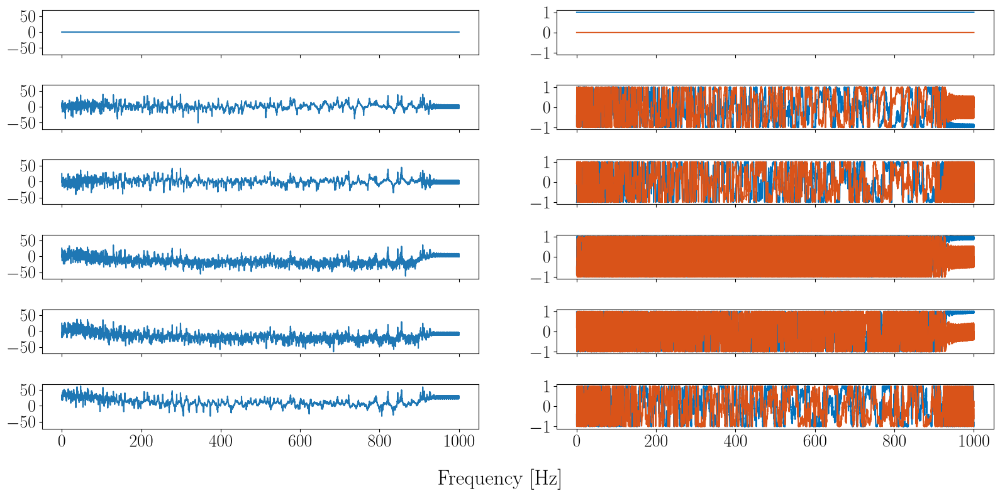

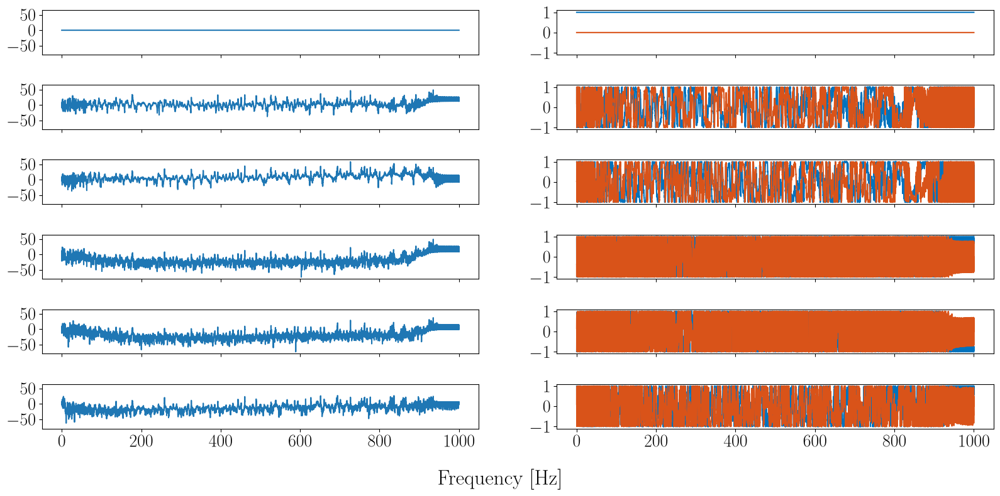

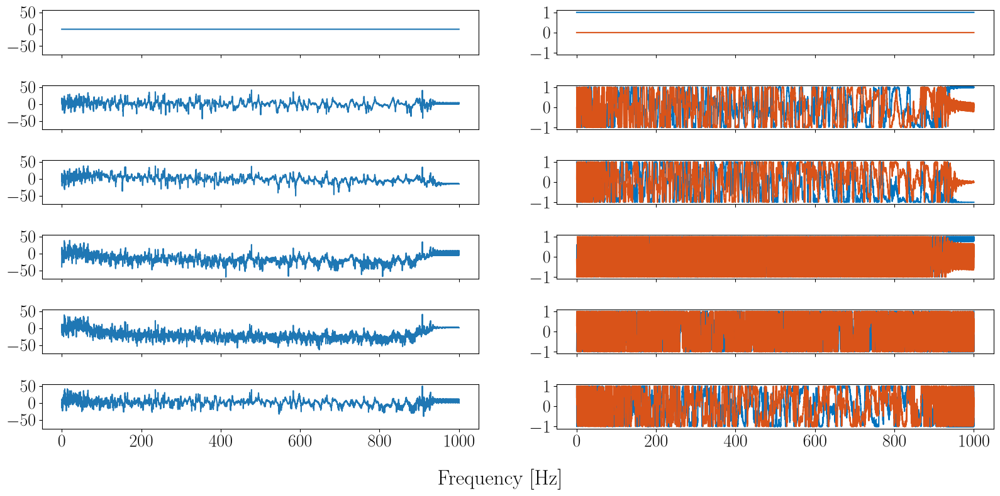

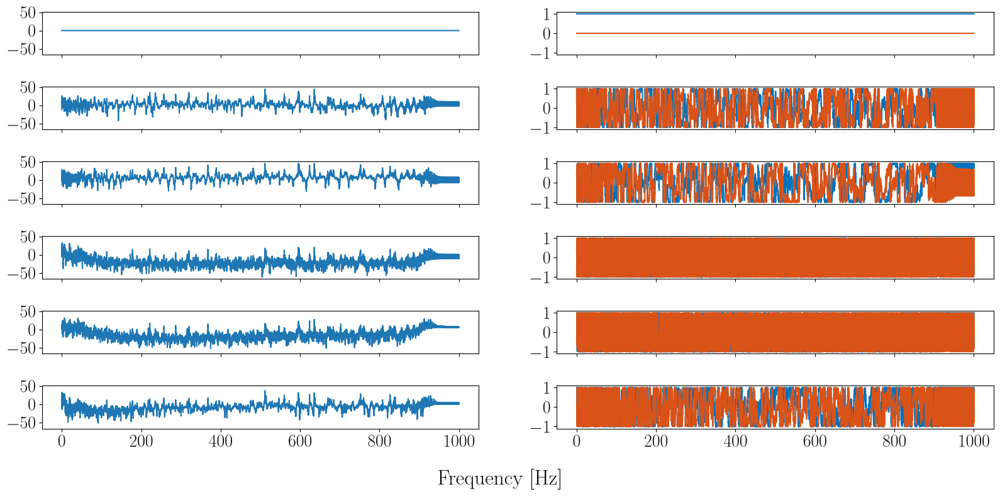

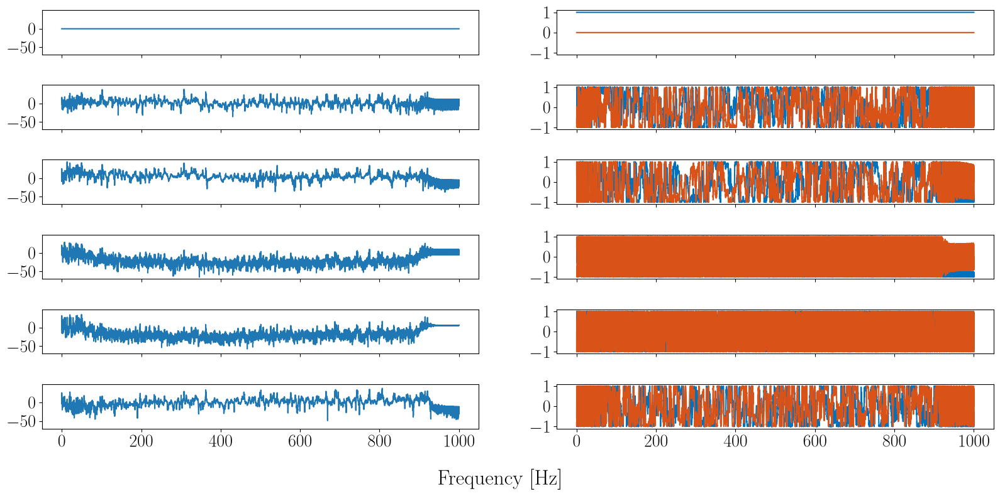

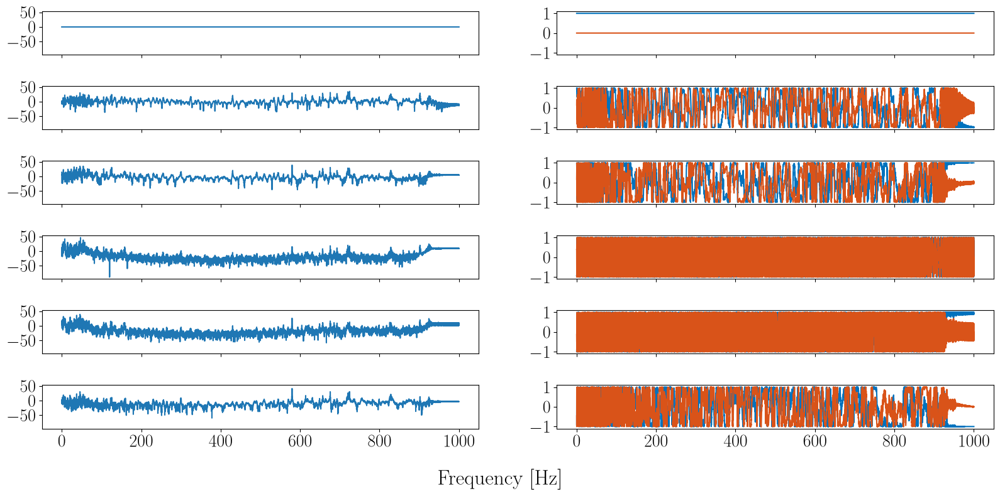

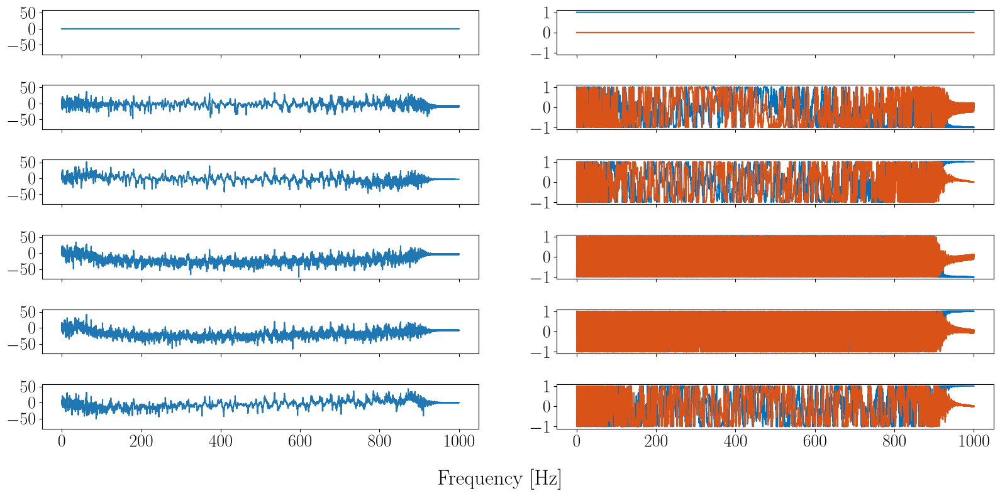

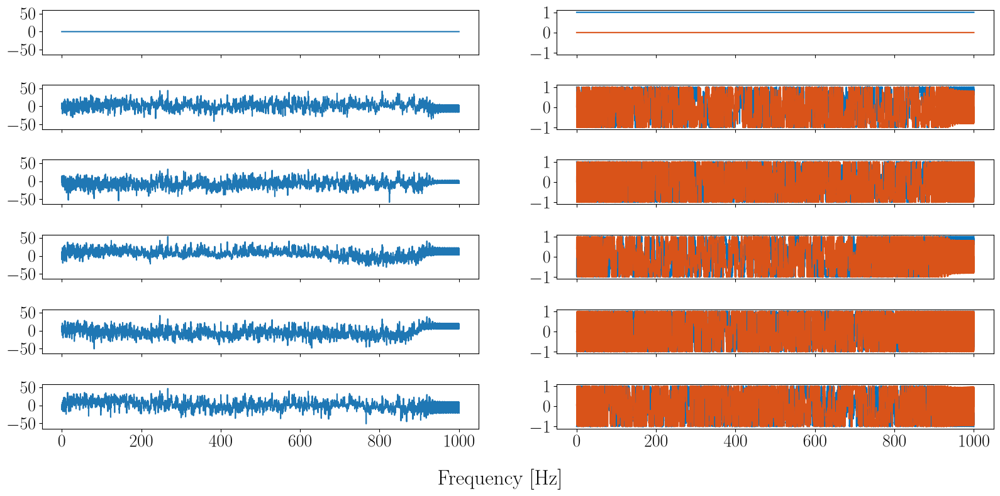

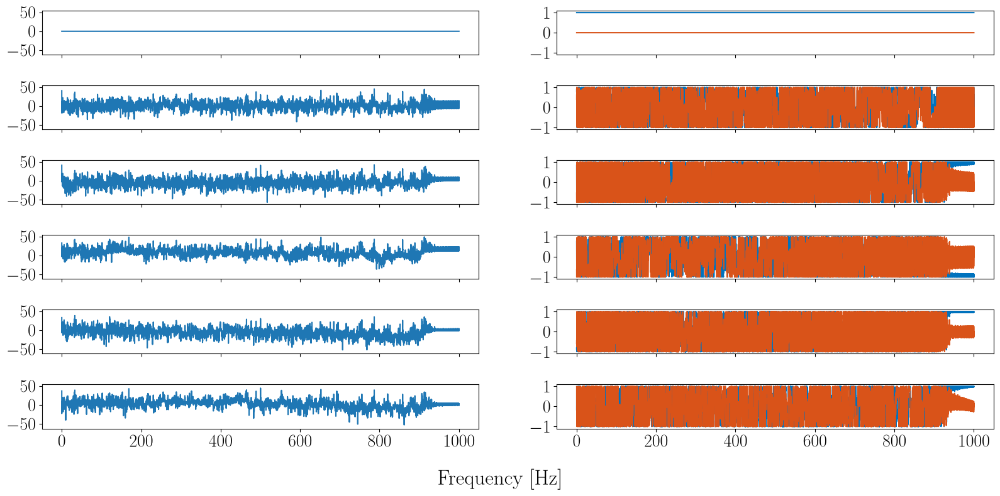

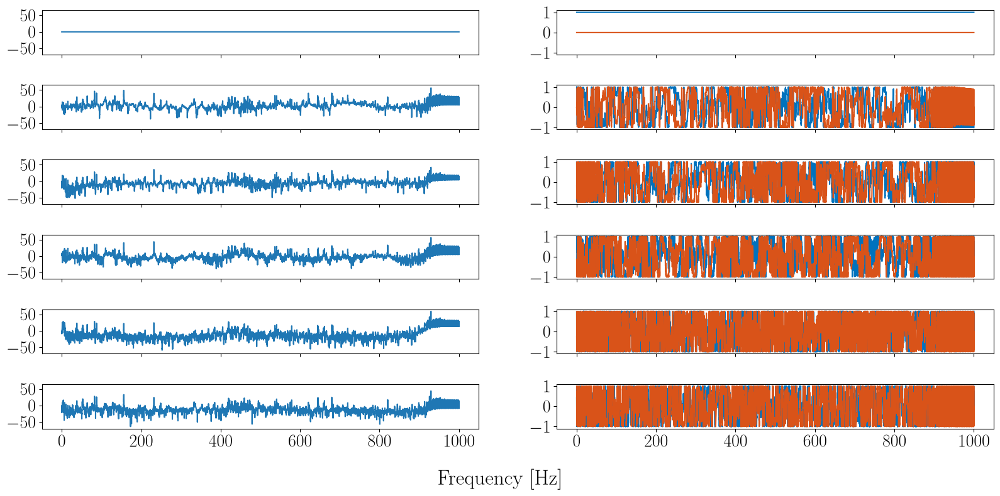

In [19]:
ref_rcv_id = "obs1"

# print(axs.shape)
for name, node in portion.feature.children.items():
    ds_feature_section = node.to_dataset()

    ds_feature_section = ds_feature_section.isel(src_datetime=0)

    sjj = ds_feature_section.sel(rcv_i=ref_rcv_id, rcv_j=ref_rcv_id).Sxy
    # Per convention : 2nd index = ref
    fig, axs = plt.subplots(nrows=obs_ids.size, ncols=2, figsize=(16, 8), sharex=True, sharey="col")

    for i_rcv, rcv_id_i in enumerate(obs_ids):

        # Sii
        sii = ds_feature_section.sel(rcv_i=rcv_id_i, rcv_j=rcv_id_i).Sxy
        # Sij
        sij = ds_feature_section.sel(rcv_i=rcv_id_i, rcv_j=ref_rcv_id).Sxy

        # RTF
        pi_ij = sij.values / sjj.values
        gamma_ij = 20 * np.log10(np.abs(pi_ij))
        # np.abs(pi_ij).plot(ax=axs[i_rcv, 0])
        # gamma_ij.plot(ax=axs[i_rcv, 0])
        axs[i_rcv, 0].plot(sij.freq, gamma_ij)

        # DCF (sxy SCOT)
        dcf_ij = sij.values / np.sqrt(sii.values * sjj.values)
        # np.real(dcf_ij).plot(ax=axs[i_rcv, 1], color=color(0))
        # np.imag(dcf_ij).plot(ax=axs[i_rcv, 1], color=color(1))
        axs[i_rcv, 1].plot(sij.freq, np.real(dcf_ij), color=color(0))
        axs[i_rcv, 1].plot(sij.freq, np.imag(dcf_ij), color=color(1))

    for ax in axs.flatten():
        ax.set_title("")
        ax.set_xlabel("")
        ax.set_ylabel("")

    fig.supxlabel("Frequency [Hz]")

/tmp/ipykernel_2709012/411726427.py:26: RuntimeWarning: invalid value encountered in divide
  pi_ij = sij.values / sjj.values
/tmp/ipykernel_2709012/411726427.py:27: RuntimeWarning: divide by zero encountered in log10
  gamma_ij = 20 * np.log10(np.abs(pi_ij))


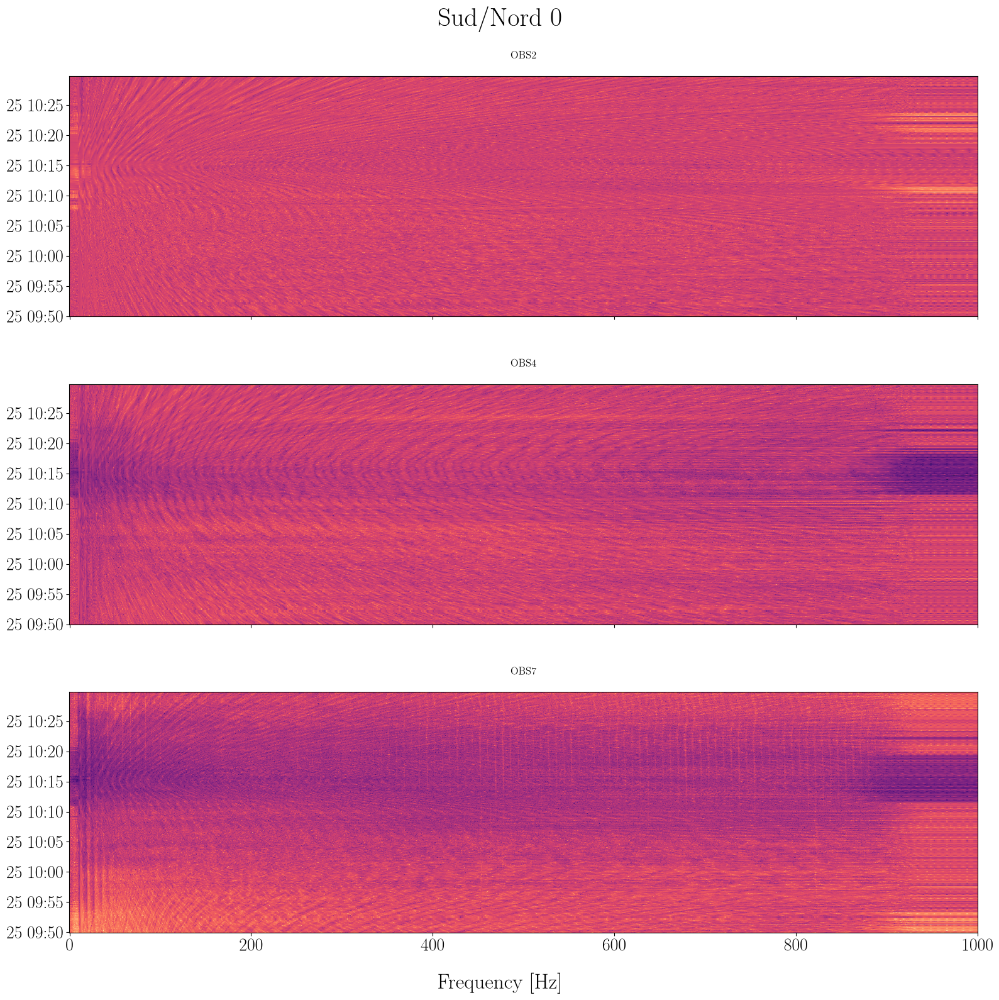

/tmp/ipykernel_2709012/411726427.py:26: RuntimeWarning: invalid value encountered in divide
  pi_ij = sij.values / sjj.values
/tmp/ipykernel_2709012/411726427.py:27: RuntimeWarning: divide by zero encountered in log10
  gamma_ij = 20 * np.log10(np.abs(pi_ij))


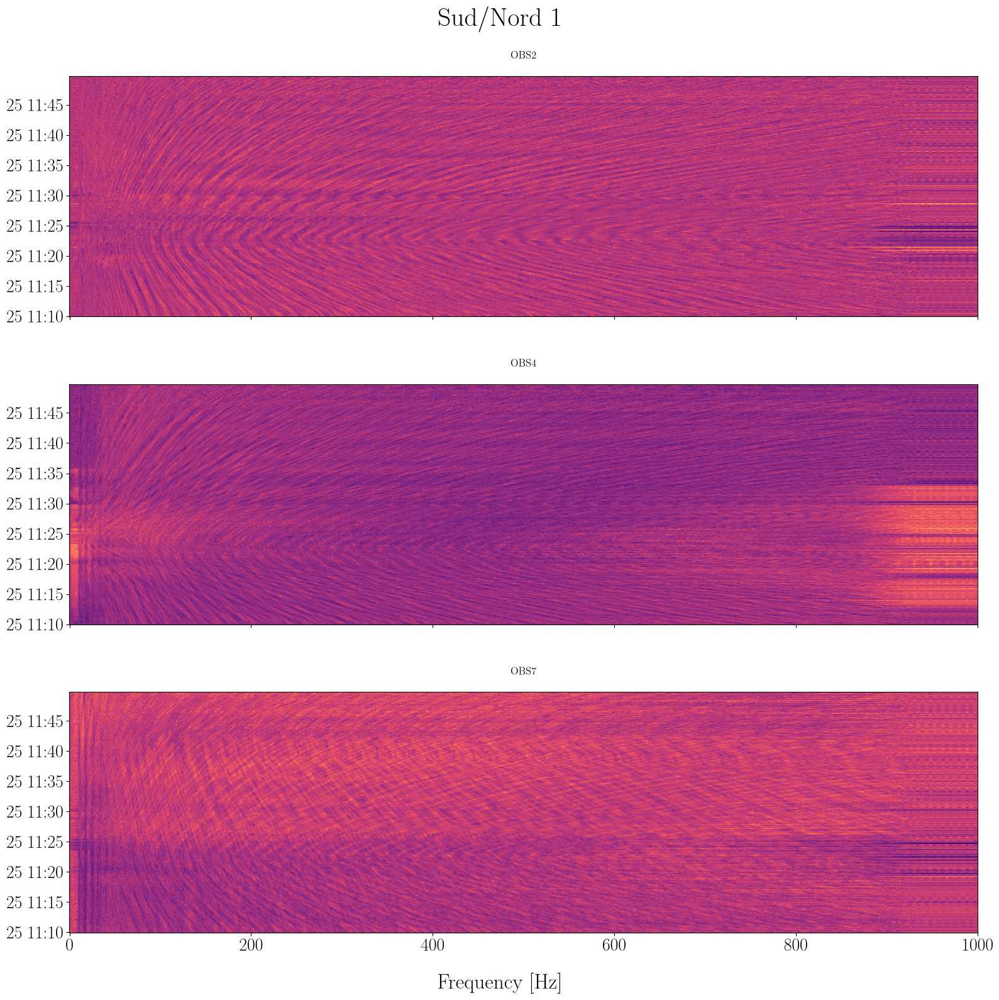

/tmp/ipykernel_2709012/411726427.py:26: RuntimeWarning: invalid value encountered in divide
  pi_ij = sij.values / sjj.values
/tmp/ipykernel_2709012/411726427.py:27: RuntimeWarning: divide by zero encountered in log10
  gamma_ij = 20 * np.log10(np.abs(pi_ij))


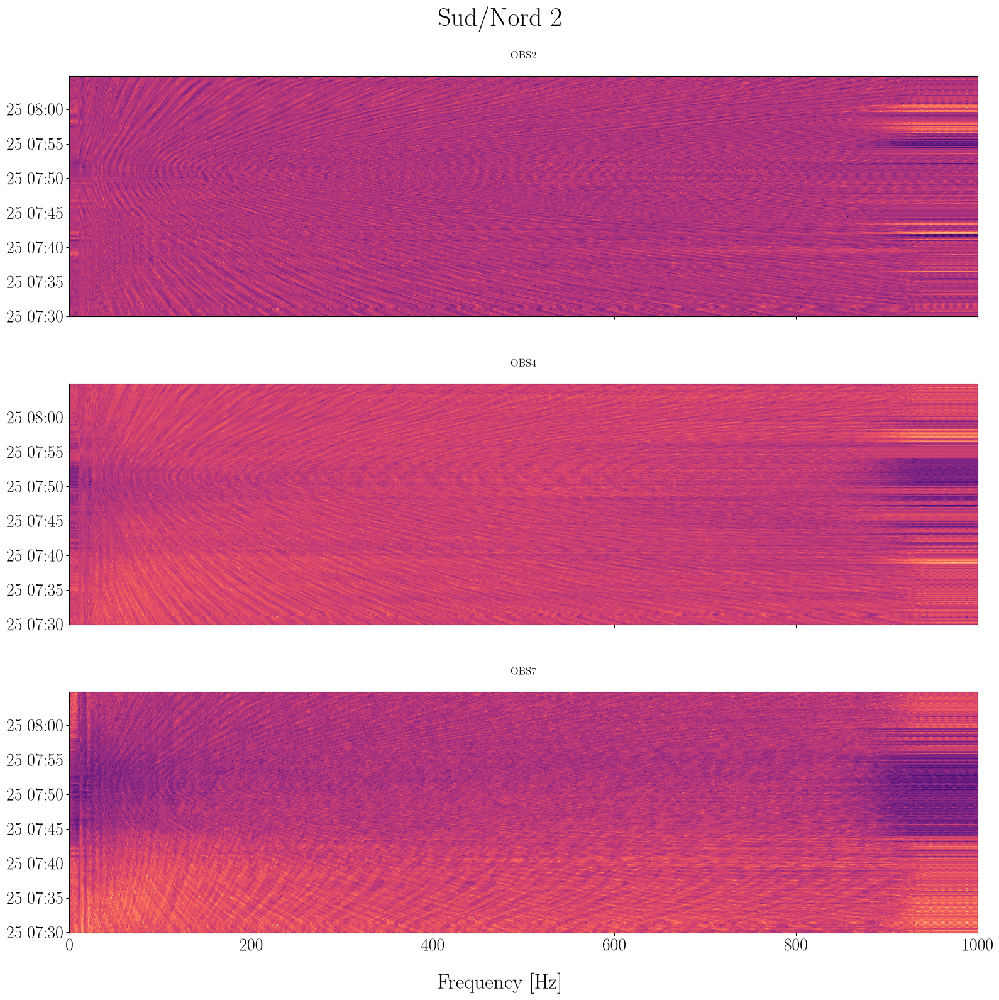

/tmp/ipykernel_2709012/411726427.py:27: RuntimeWarning: divide by zero encountered in log10
  gamma_ij = 20 * np.log10(np.abs(pi_ij))


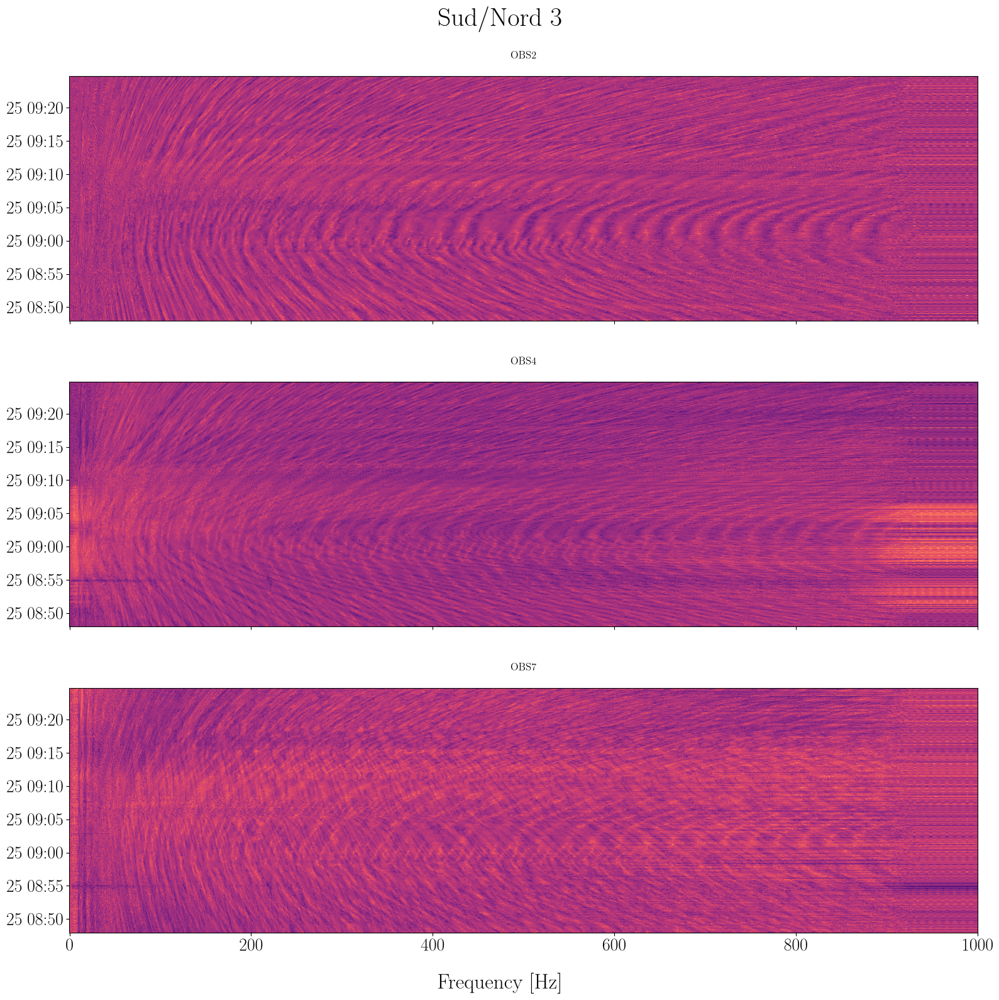

/tmp/ipykernel_2709012/411726427.py:26: RuntimeWarning: invalid value encountered in divide
  pi_ij = sij.values / sjj.values
/tmp/ipykernel_2709012/411726427.py:27: RuntimeWarning: divide by zero encountered in log10
  gamma_ij = 20 * np.log10(np.abs(pi_ij))


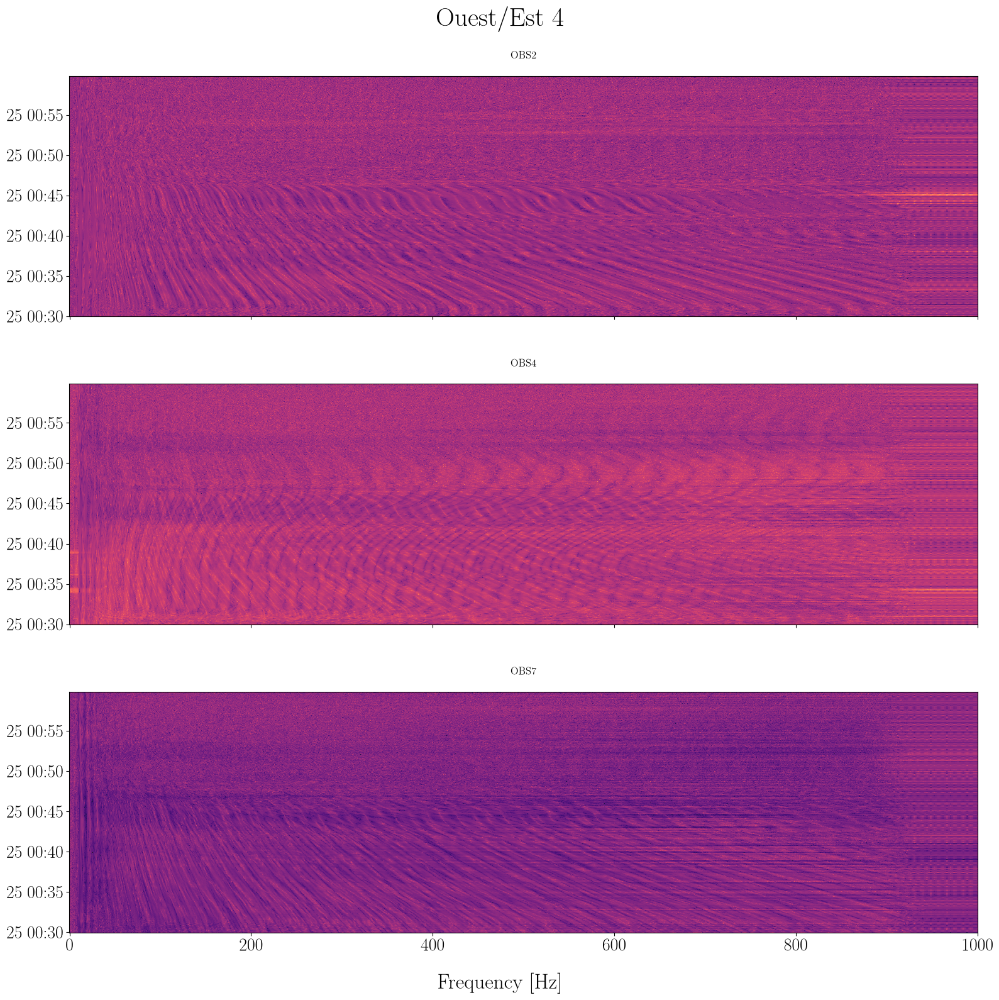

/tmp/ipykernel_2709012/411726427.py:26: RuntimeWarning: invalid value encountered in divide
  pi_ij = sij.values / sjj.values
/tmp/ipykernel_2709012/411726427.py:27: RuntimeWarning: divide by zero encountered in log10
  gamma_ij = 20 * np.log10(np.abs(pi_ij))


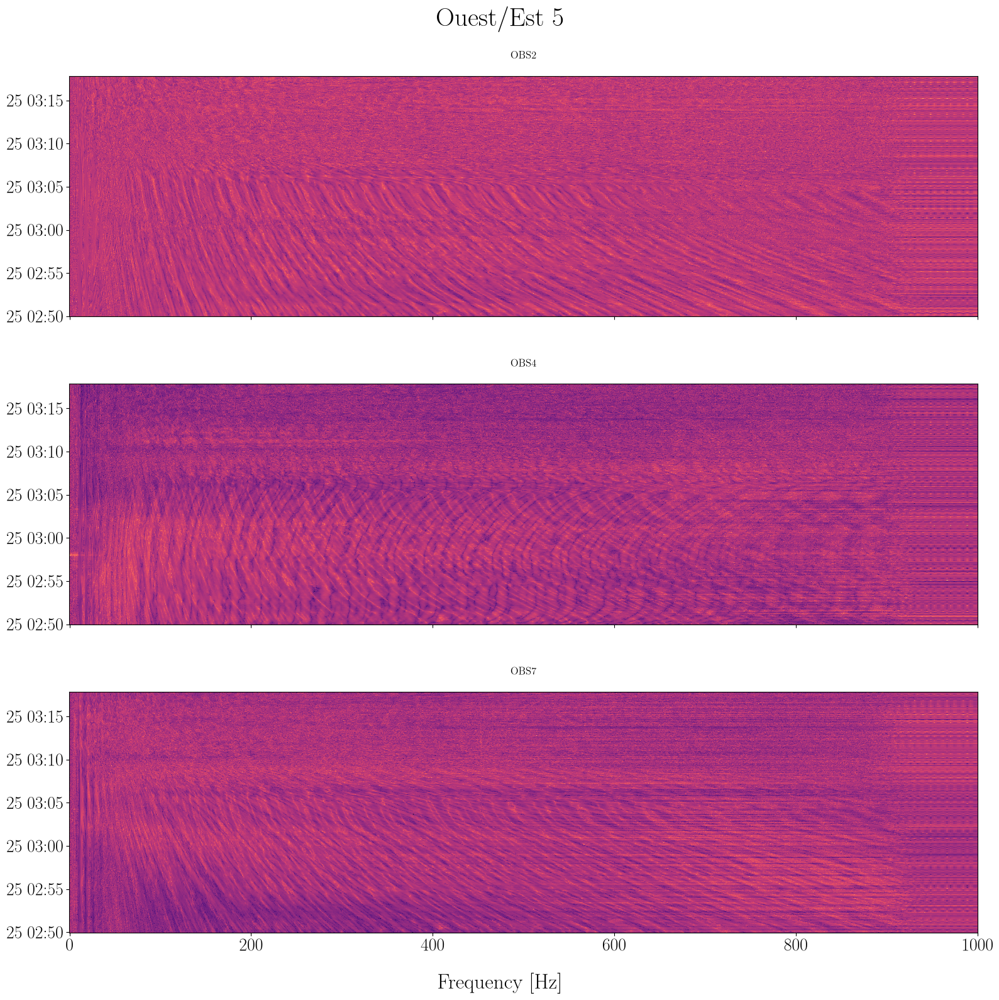

/tmp/ipykernel_2709012/411726427.py:26: RuntimeWarning: invalid value encountered in divide
  pi_ij = sij.values / sjj.values
/tmp/ipykernel_2709012/411726427.py:27: RuntimeWarning: divide by zero encountered in log10
  gamma_ij = 20 * np.log10(np.abs(pi_ij))


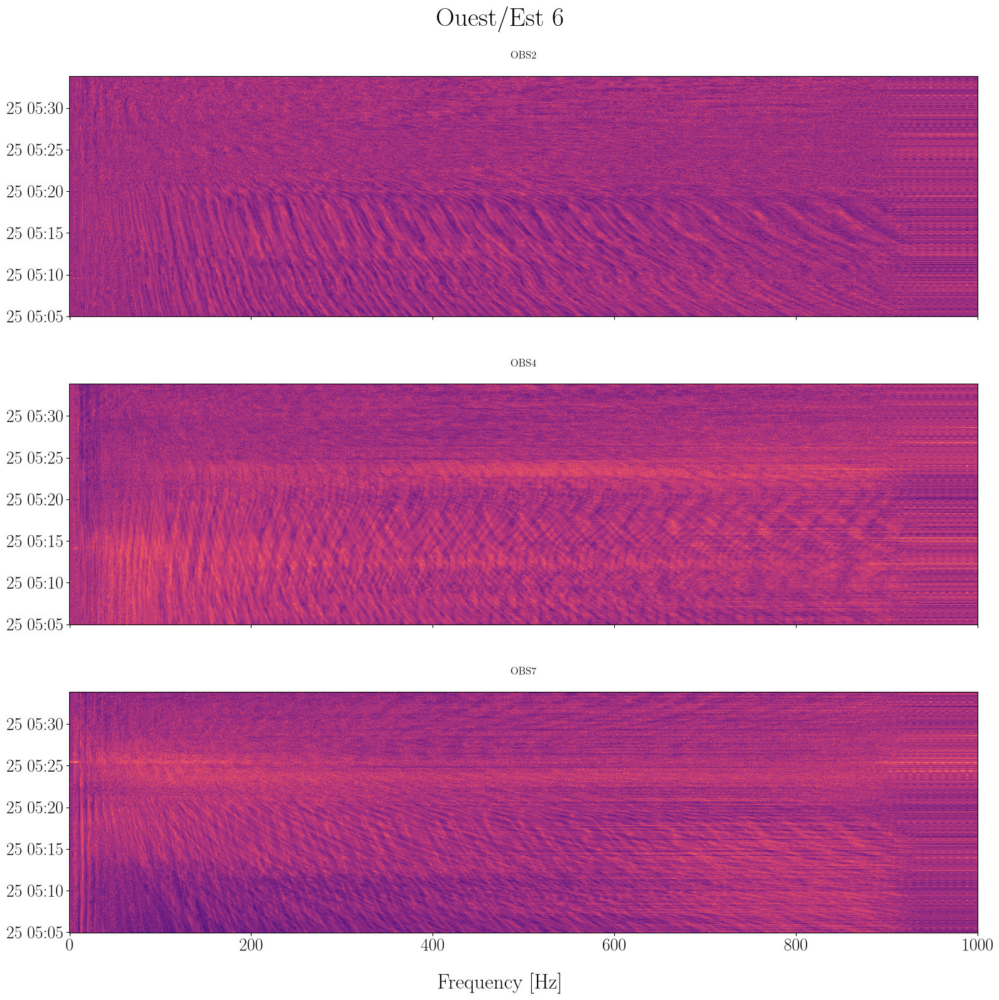

/tmp/ipykernel_2709012/411726427.py:27: RuntimeWarning: divide by zero encountered in log10
  gamma_ij = 20 * np.log10(np.abs(pi_ij))


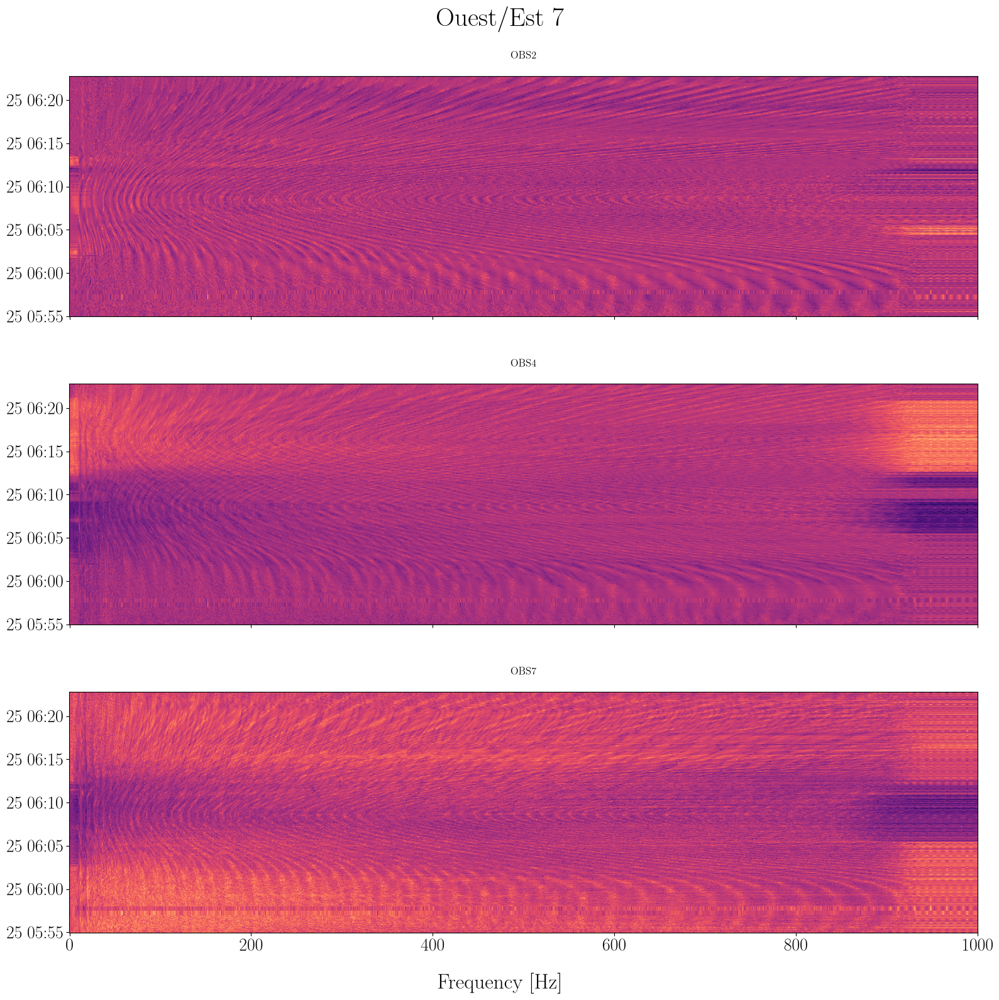

/tmp/ipykernel_2709012/411726427.py:27: RuntimeWarning: divide by zero encountered in log10
  gamma_ij = 20 * np.log10(np.abs(pi_ij))


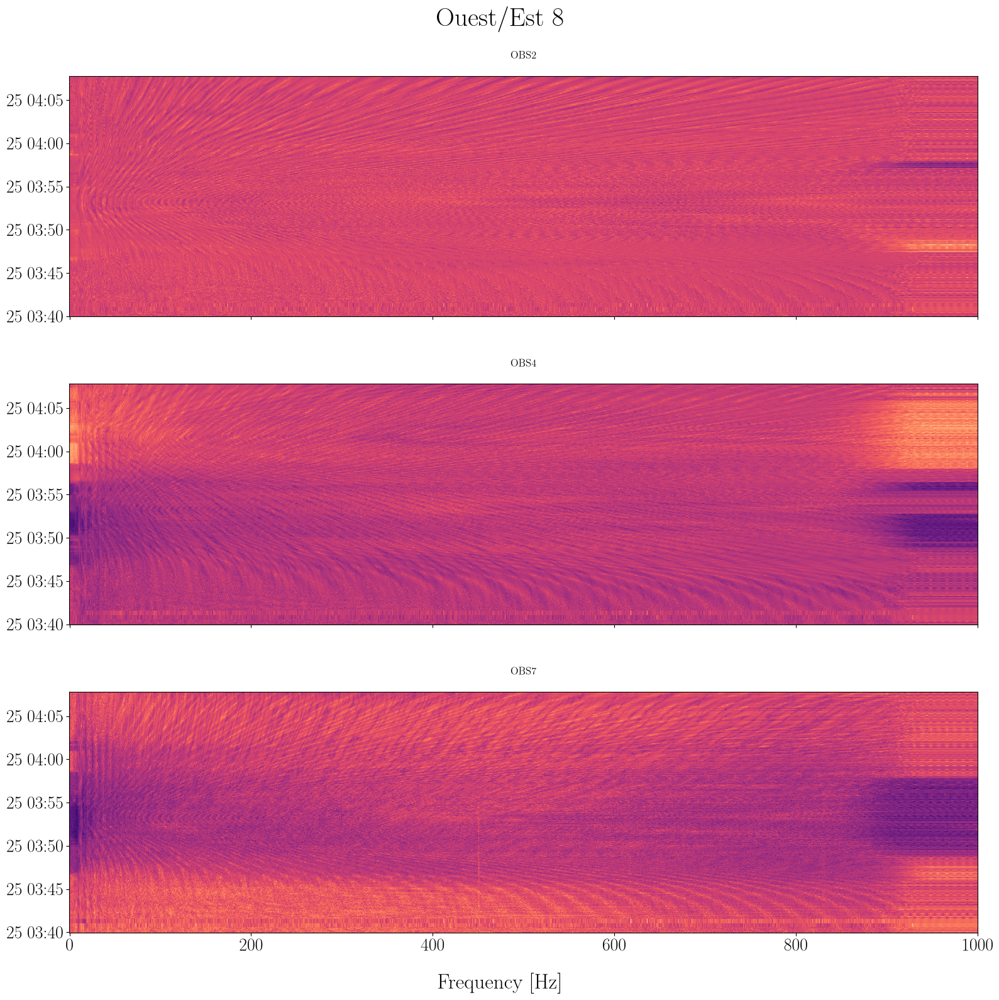

/tmp/ipykernel_2709012/411726427.py:26: RuntimeWarning: invalid value encountered in divide
  pi_ij = sij.values / sjj.values
/tmp/ipykernel_2709012/411726427.py:27: RuntimeWarning: divide by zero encountered in log10
  gamma_ij = 20 * np.log10(np.abs(pi_ij))


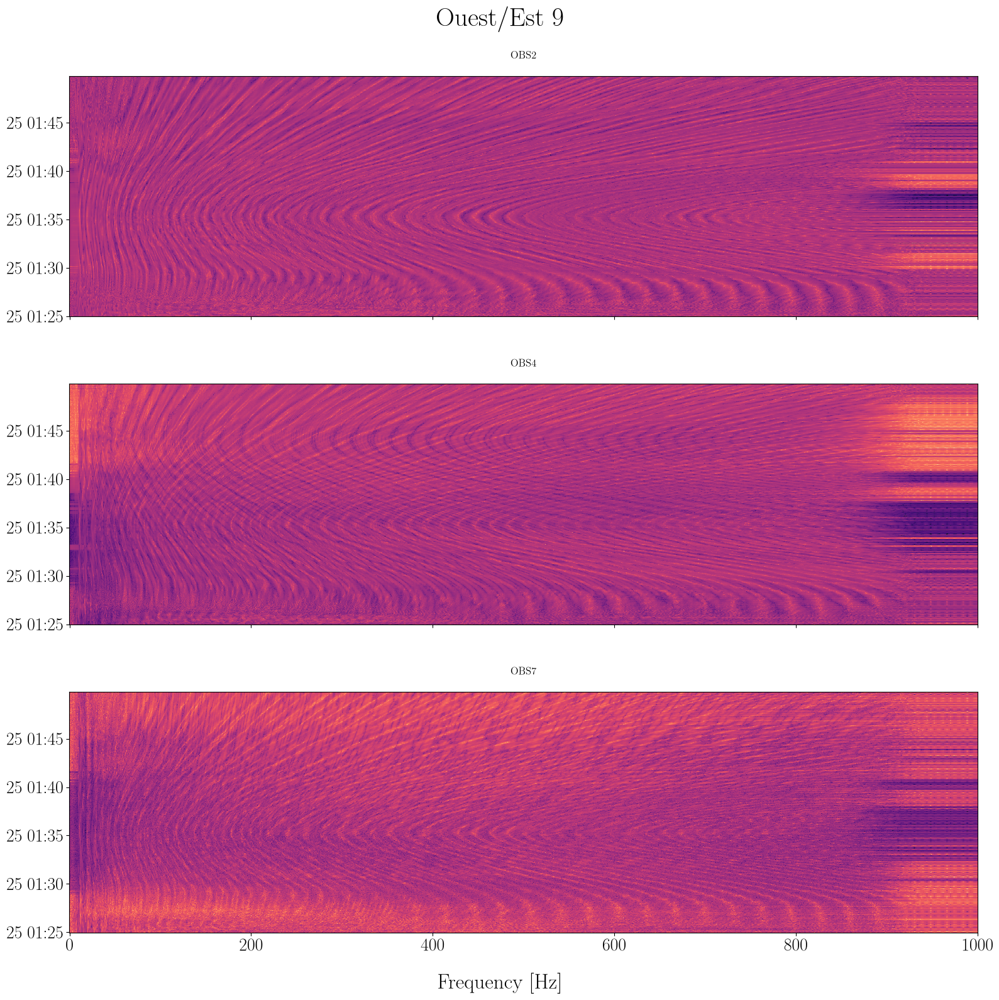

In [20]:
ref_rcv_id = "obs1"
obs_ids_visu = obs_ids[[0, 1, 2, -1]]

# print(axs.shape)
for name, node in portion.feature.children.items():
    ds_feature_section = node.to_dataset()

    sjj = ds_feature_section.sel(rcv_i=ref_rcv_id, rcv_j=ref_rcv_id).Sxy
    # Per convention : 2nd index = ref

    fig, axs = plt.subplots(
        nrows=obs_ids_visu.size-1, ncols=1, figsize=(16, 16), sharex=True, sharey=True
    )
    axs = axs.flatten()
    iplot = 0
    for i_rcv, rcv_id_i in enumerate(obs_ids_visu):

        if rcv_id_i == ref_rcv_id:
            continue
        # Sii
        sii = ds_feature_section.sel(rcv_i=rcv_id_i, rcv_j=rcv_id_i).Sxy
        # Sij
        sij = ds_feature_section.sel(rcv_i=rcv_id_i, rcv_j=ref_rcv_id).Sxy

        # RTF
        pi_ij = sij.values / sjj.values
        gamma_ij = 20 * np.log10(np.abs(pi_ij))
        # np.abs(pi_ij).plot(ax=axs[i_rcv, 0])
        # gamma_ij.plot(x="freq", ax=axs[iplot], cmap="magma", add_colorbar=False)
        axs[iplot].pcolormesh(sij.freq, sij.src_datetime, gamma_ij, cmap="magma")

        axs[iplot].set_xlabel("")
        axs[iplot].set_ylabel("")
        # axs[iplot].set_title("")
        axs[iplot].set_title(rcv_id_i.upper(), fontsize=12)
        iplot += 1

    fig.supxlabel("Frequency [Hz]")
    fig.suptitle(
        f"{ds_feature_section.section_orientation} {ds_feature_section.section_id}"
    )
    # plt.xlim(100, 200)
    plt.show()

    # # DCF (sxy SCOT)
    # dcf_ij = sij / np.sqrt(sii * sjj)
    # np.real(dcf_ij).plot(ax=axs[i_rcv, 1], color=color(0))
    # np.imag(dcf_ij).plot(ax=axs[i_rcv, 1], color=color(1))

    # for ax in axs.flatten():
    #     ax.set_title("")
    #     ax.set_xlabel("")
    #     ax.set_ylabel("")

    # fig.supxlabel("Frequency [Hz]")

# Etude des intersections 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

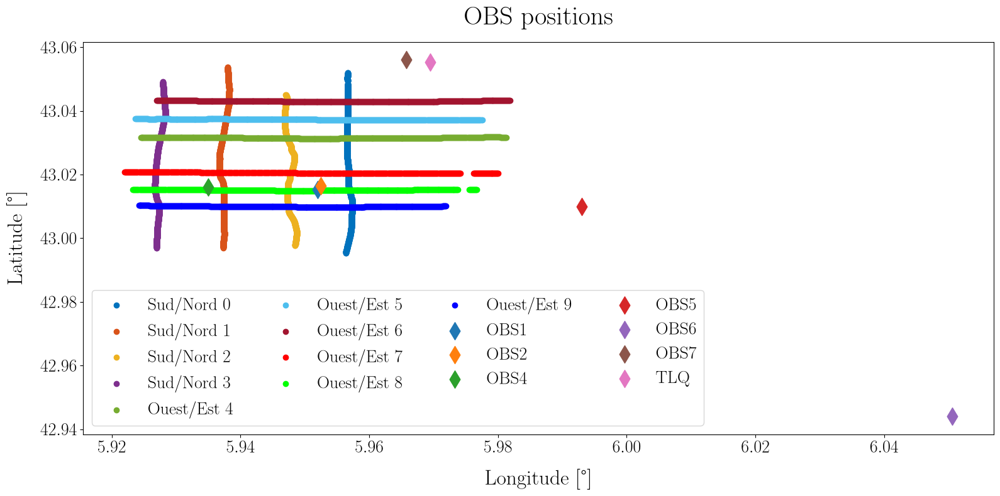

In [21]:
plot_portion_tir_pos(portion_tree=portion)

## Analyse d'une section 

In [47]:
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB 43.05 43.05 ... 43.0 43.0
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB 4.11e+03 ... ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB 2.726 ... 4.475
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               4
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/sn2
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 17kB ...
│   │           atl_lat                 (atl_datetime) float64 17kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB 43.0 43.0 ... 43.05 43.05
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 45kB 2.354e+03 ......
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 45kB 1.563 ... 1.705
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 45kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │          

In [184]:
section_1_name = "sn2"
section_2_name = "oe1"
ds_feature_section1 = portion.feature[section_1_name].to_dataset()
ds_feature_section2 = portion.feature[section_2_name].to_dataset()

### CPA 

In [185]:
dist_12 = get_distance_between_sections(ds_feature_section1, ds_feature_section2)

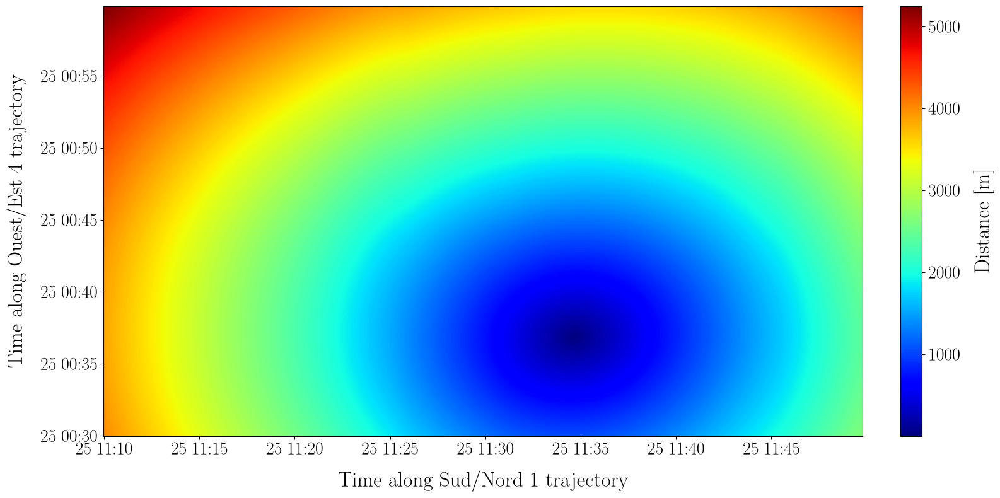

In [186]:
im = plt.pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_12,
    cmap="jet",
)
plt.xlabel(f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory")
plt.ylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)
plt.colorbar(im, label="Distance [m]")

### Distance dans l'espace des données 

In [187]:
rcv_id_i = "obs2"
ref_rcv_id = "obs1"

fmin = 5
fmax = 50

pi_ij_a, gamma_a, sij_scot_a = derive_section_features(
    ds_feature_section=ds_feature_section1,
    fmin=fmin,
    fmax=fmax,
    rcv_ref=ref_rcv_id,
    rcv_i=rcv_id_i,
)
pi_ij_b, gamma_b, sij_scot_b = derive_section_features(
    ds_feature_section=ds_feature_section2,
    fmin=fmin,
    fmax=fmax,
    rcv_ref=ref_rcv_id,
    rcv_i=rcv_id_i,
)

In [188]:
features_section1 = dict(pi_ij=pi_ij_a, gamma_ij=gamma_a, sij_scot=sij_scot_a)
features_section2 = dict(pi_ij=pi_ij_b, gamma_ij=gamma_b, sij_scot=sij_scot_b)

dist_theta, dist_theta_gamma, dist_L2_gamma, dist_dcf = (
    derive_feature_distance_between_sections(features_section1, features_section2)
)

In [189]:
xmin, ymin = find_min_distance_position(dt1=ds_feature_section1.src_datetime, dt2=ds_feature_section2.src_datetime, dist=dist_12)

# Theta with pi
xmin_theta, ymin_theta = find_min_distance_position(
    dt1=ds_feature_section1.src_datetime,
    dt2=ds_feature_section2.src_datetime,
    dist=dist_theta.T,
)

# Theta with gamma
xmin_theta_gamma, ymin_theta_gamma = find_min_distance_position(
    dt1=ds_feature_section1.src_datetime,
    dt2=ds_feature_section2.src_datetime,
    dist=dist_theta_gamma.T,
)

# L2 with gamma
xmin_L2_gamma, ymin_L2_gamma = find_min_distance_position(
    dt1=ds_feature_section1.src_datetime,
    dt2=ds_feature_section2.src_datetime,
    dist=dist_L2_gamma.T,
)

# DCF
xmin_dcf, ymin_dcf = find_min_distance_position(
    dt1=ds_feature_section1.src_datetime,
    dt2=ds_feature_section2.src_datetime,
    dist=dist_dcf.T,
)

#### R vs theta 

Text(0.02, 0.5, 'Time along Ouest/Est 4 trajectory')

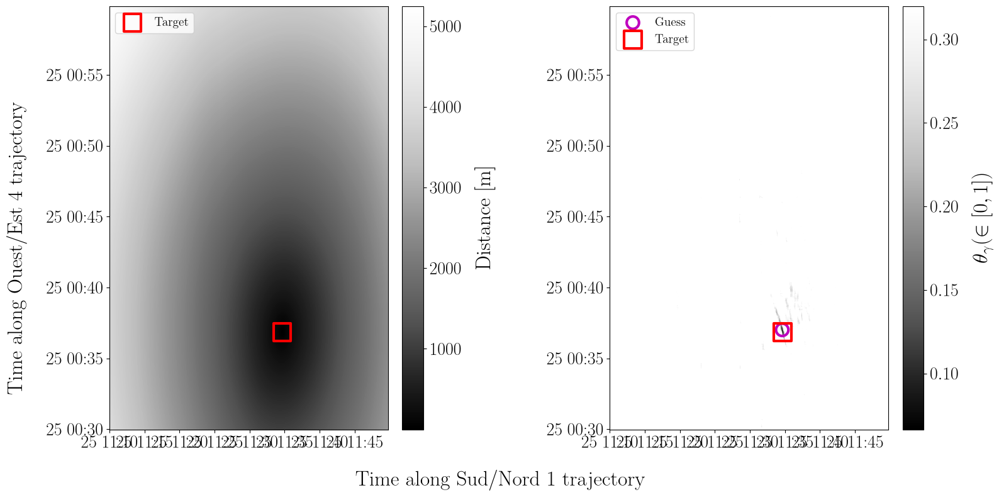

In [190]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_12,
    cmap="Grays_r",
)
plt.colorbar(im, ax=axs[0], label="Distance [m]")
im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta_gamma.T,
    cmap="Grays_r",
    vmin=np.nanmin(dist_theta_gamma),
    vmax=np.nanpercentile(dist_theta_gamma, 0.5),
)
plt.colorbar(im, ax=axs[1], label=r"$\theta_{\gamma} (\in [0, 1])$")

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[1].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

#### $\theta_{\gamma}$ vs $\theta_{\Pi}$ 

Text(0.02, 0.5, 'Time along Ouest/Est 4 trajectory')

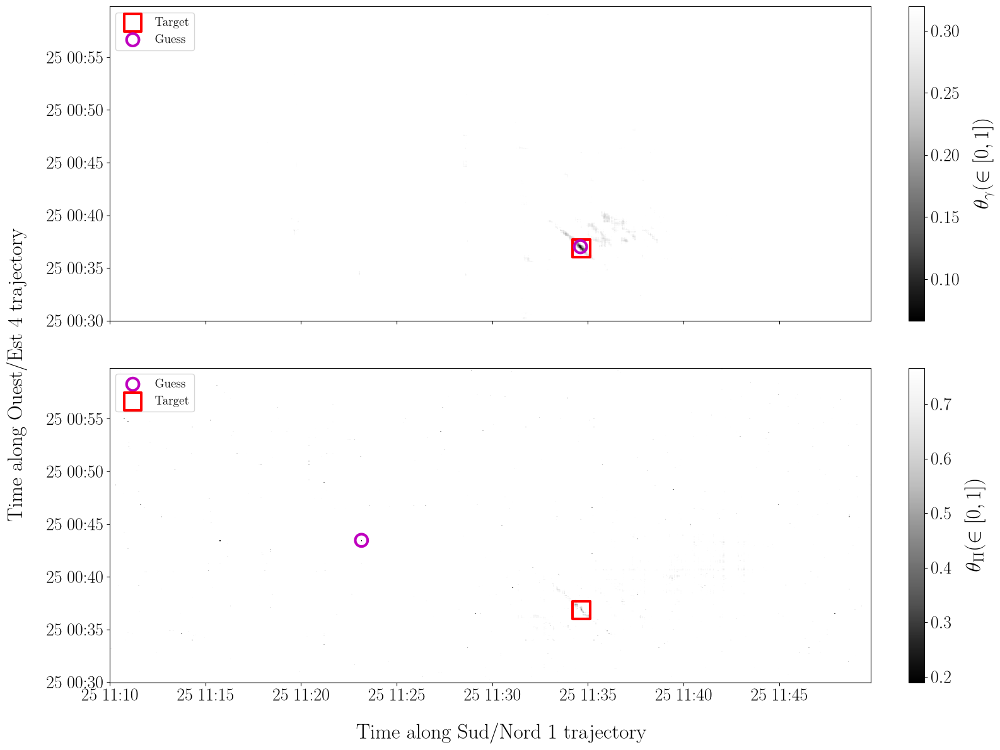

In [191]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(16, 12), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    vmin=np.nanmin(dist_theta_gamma),
    vmax=np.nanpercentile(dist_theta_gamma, 0.5),
)
plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma} (\in [0, 1])$")
im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta.T,
    cmap="Grays_r",
    vmin=np.nanmin(dist_theta),
    vmax=np.nanpercentile(dist_theta, 0.5),
)
plt.colorbar(im, ax=axs[1], label=r"$\theta_{\Pi} (\in [0, 1])$")

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin_theta,
    ymin_theta,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

#### $\theta_{\gamma}$ vs $\theta_{\Pi}$ vs $L2_{\gamma}$

Text(0.02, 0.5, 'Time along Ouest/Est 4 trajectory')

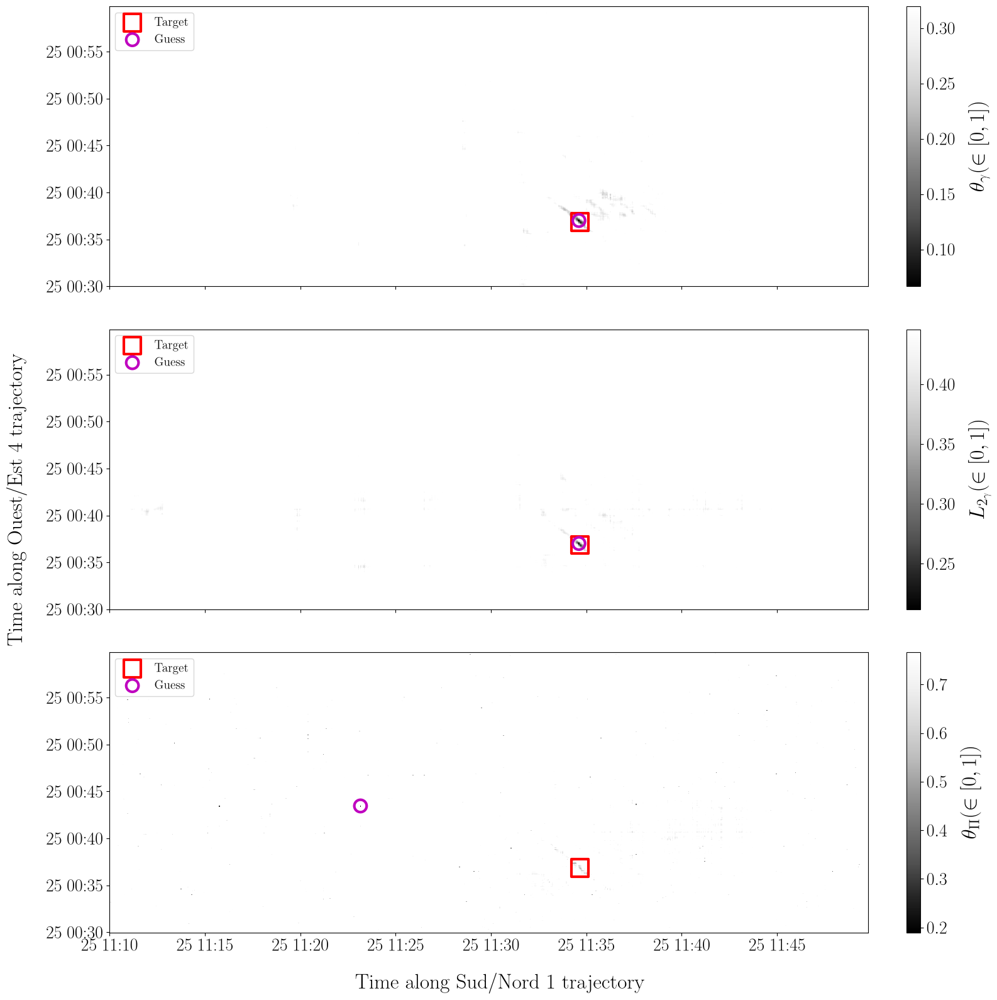

In [192]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 16), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    vmin=np.nanmin(dist_theta_gamma),
    vmax=np.nanpercentile(dist_theta_gamma, 0.5),
)
plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma} (\in [0, 1])$")

im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_L2_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_L2_gamma, 0.1),
    vmin=np.nanmin(dist_L2_gamma),
    vmax=np.nanpercentile(dist_L2_gamma, 0.5),
)
plt.colorbar(im, ax=axs[1], label=r"$L_{2_{\gamma}} (\in [0, 1])$")

im = axs[2].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta, 0.1),
    vmin=np.nanmin(dist_theta),
    vmax=np.nanpercentile(dist_theta, 0.5),
)
plt.colorbar(im, ax=axs[2], label=r"$\theta_{\Pi} (\in [0, 1])$")
axs[2].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[2].scatter(
    xmin_theta,
    ymin_theta,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[1].scatter(
    xmin_L2_gamma,
    ymin_L2_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)




for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

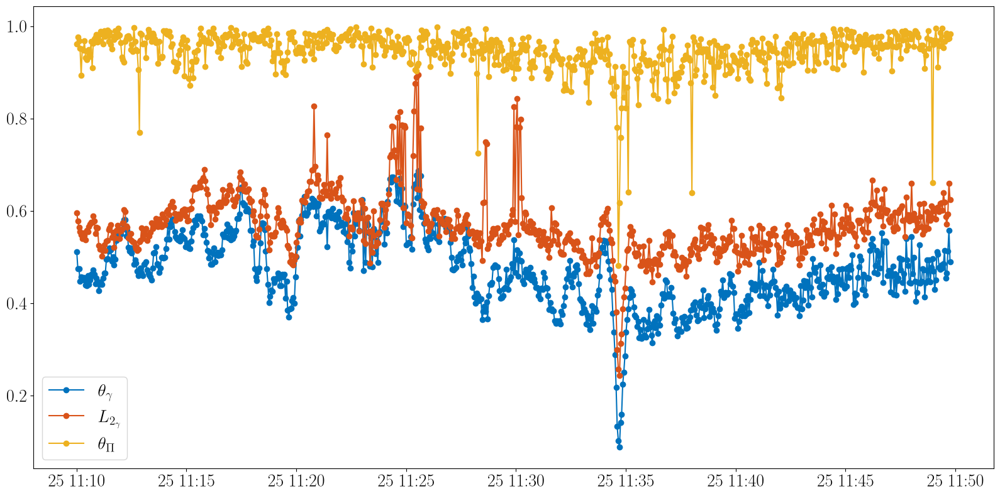

In [193]:
idx_ymin_theta_gamma = np.abs(ds_feature_section2.src_datetime - ymin_theta_gamma).argmin(dim="src_datetime")
idx_ymin = np.abs(ds_feature_section2.src_datetime - ymin).argmin(dim="src_datetime")
line_theta_gamma = dist_theta_gamma[:, idx_ymin]

# idx_ymin_theta = np.abs(src_lon2.src_datetime - ymin_theta).argmin(dim="src_datetime")
line_theta = dist_theta[:, idx_ymin]

# idx_ymin_L2_gamma = np.abs(src_lon2.src_datetime - ymin_L2_gamma).argmin(dim="src_datetime")
line_L2_gamma = dist_L2_gamma[:, idx_ymin]

plt.figure()
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta_gamma,
    "-o",
    color=color(0),
    label=r"$\theta_{\gamma}$",
)
plt.plot(
    ds_feature_section1.src_datetime,
    line_L2_gamma,
    "-o",
    color=color(1),
    label=r"$L_{2_{\gamma}}$",
)
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta,
    "-o",
    color=color(2),
    label=r"$\theta_{\Pi}$",
)
plt.legend()

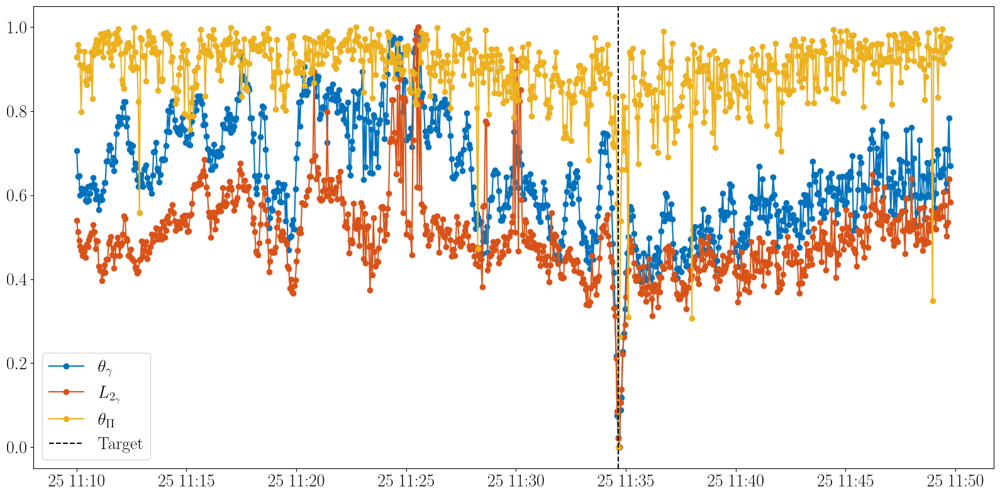

In [194]:
line_theta_gamma = (line_theta_gamma - np.nanmin(line_theta_gamma)) / (np.nanmax(line_theta_gamma) - np.nanmin(line_theta_gamma))
line_theta = (line_theta - np.nanmin(line_theta)) / (np.nanmax(line_theta) - np.nanmin(line_theta))
line_L2_gamma = (line_L2_gamma - np.nanmin(line_L2_gamma)) / (np.nanmax(line_L2_gamma) - np.nanmin(line_L2_gamma))

plt.figure()
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta_gamma,
    "-o",
    color=color(0),
    label=r"$\theta_{\gamma}$",
)
plt.plot(
    ds_feature_section1.src_datetime,
    line_L2_gamma,
    "-o",
    color=color(1),
    label=r"$L_{2_{\gamma}}$",
)
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta,
    "-o",
    color=color(2),
    label=r"$\theta_{\Pi}$",
)
plt.axvline(xmin, color="k", linestyle="--", label="Target")
plt.legend()

Les trois distances présentent un minimum à la position attendue. Comme précédemment observé, le domaine de monotonie est très faible quelle que soit la distance ! 

(np.float64(20509.481708334468), np.float64(20509.483097223354))

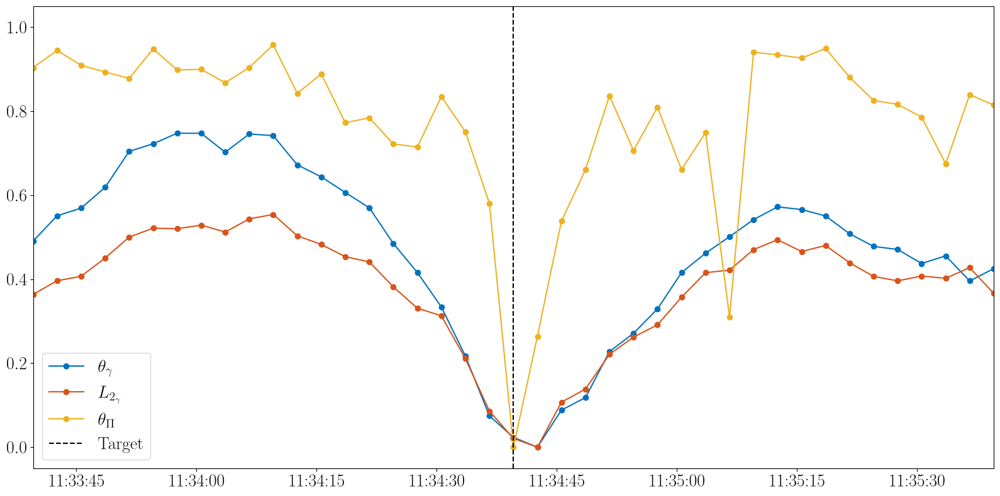

In [195]:
line_theta_gamma = (line_theta_gamma - np.nanmin(line_theta_gamma)) / (
    np.nanmax(line_theta_gamma) - np.nanmin(line_theta_gamma)
)
line_theta = (line_theta - np.nanmin(line_theta)) / (
    np.nanmax(line_theta) - np.nanmin(line_theta)
)
line_L2_gamma = (line_L2_gamma - np.nanmin(line_L2_gamma)) / (
    np.nanmax(line_L2_gamma) - np.nanmin(line_L2_gamma)
)

plt.figure()
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta_gamma,
    "-o",
    color=color(0),
    label=r"$\theta_{\gamma}$",
)
plt.plot(
    ds_feature_section1.src_datetime,
    line_L2_gamma,
    "-o",
    color=color(1),
    label=r"$L_{2_{\gamma}}$",
)
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta,
    "-o",
    color=color(2),
    label=r"$\theta_{\Pi}$",
)
plt.axvline(xmin, color="k", linestyle="--", label="Target")
plt.legend()
plt.xlim(xmin - np.timedelta64(60, "s"), xmin + np.timedelta64(60, "s"))

On dénombre seulement une dizaine de points dans le lobe principale.  

La vitesse moyenne de la source est identique sur les deux trajectoires $\approx$ 2.6 m/s. L'intervalle inter-tir est de 3 s, pour 10 tirs on a donc un déplacement d'environ 25 m. 


### Comparaison à la méthode DCF 

#### R vs dcf

Text(0.02, 0.5, 'Time along Ouest/Est 4 trajectory')

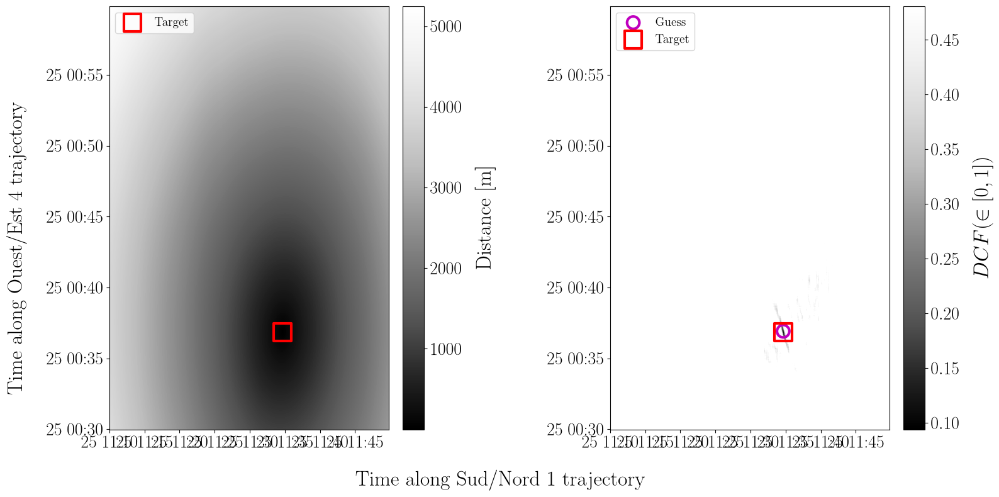

In [196]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_12,
    cmap="Grays_r",
)
plt.colorbar(im, ax=axs[0], label="Distance [m]")
im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_dcf.T,
    cmap="Grays_r",
    vmin=np.nanmin(dist_dcf),
    vmax=np.nanpercentile(dist_dcf, 0.5),
)
plt.colorbar(im, ax=axs[1], label=r"$DCF (\in [0, 1])$")

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[1].scatter(
    xmin_dcf,
    ymin_dcf,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

#### $\theta_{\gamma}$ vs DCF 

Text(0.02, 0.5, 'Time along Ouest/Est 4 trajectory')

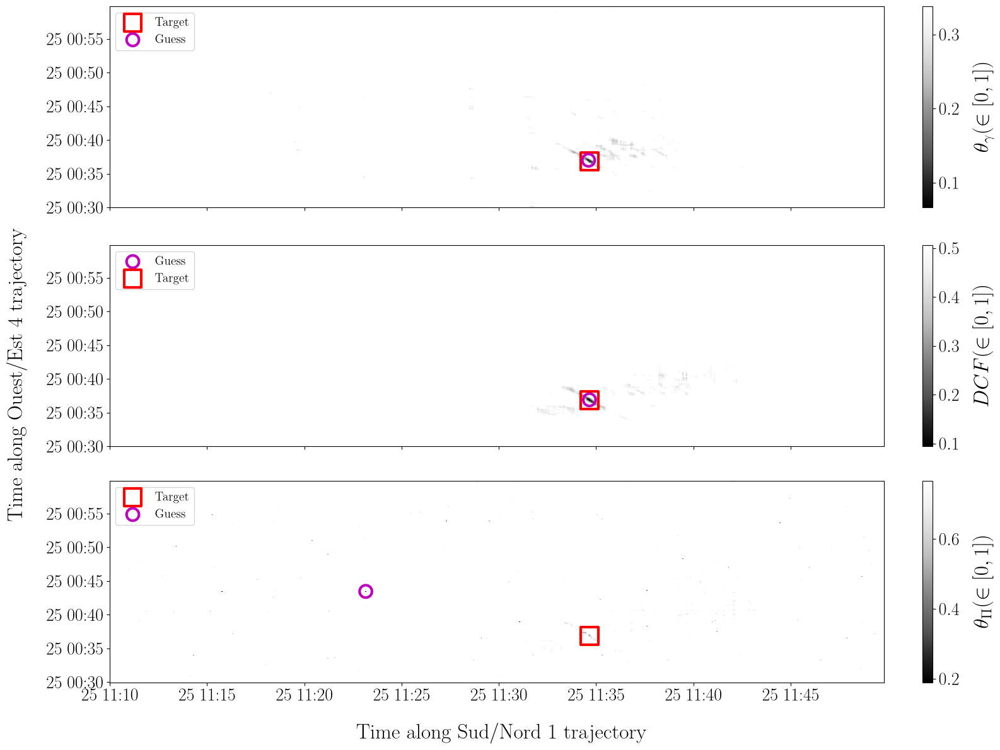

In [197]:
# vmin = max(np.nanmin(dist_theta_gamma), np.nanmin(dist_dcf))
# vmax = min(np.nanpercentile(dist_theta_gamma, 0.75), np.nanpercentile(dist_dcf, 0.75))


fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 12), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    vmin=np.nanmin(dist_theta_gamma),
    vmax=np.nanpercentile(dist_theta_gamma, 0.99),
    # vmin=vmin,
    # vmax=vmax,
)
plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma} (\in [0, 1])$")
im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_dcf.T,
    cmap="Grays_r",
    vmin=np.nanmin(dist_dcf),
    vmax=np.nanpercentile(dist_dcf, 0.99),
    # vmin=vmin,
    # vmax=vmax,
)
plt.colorbar(im, ax=axs[1], label=r"$DCF (\in [0, 1])$")

im = axs[2].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta, 0.1),
    vmin=np.nanmin(dist_theta),
    vmax=np.nanpercentile(dist_theta, 0.5),
)
plt.colorbar(im, ax=axs[2], label=r"$\theta_{\Pi} (\in [0, 1])$")
axs[2].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[2].scatter(
    xmin_theta,
    ymin_theta,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin_dcf,
    ymin_dcf,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

Afin de comparer les deux approches on normalise afin d'avoir des variations dans la pleine échelle [0, 1]

In [198]:
dist_dcf_norm = (dist_dcf - np.nanmin(dist_dcf)) / (np.nanmax(dist_dcf) - np.nanmin(dist_dcf))
dist_theta_gamma_norm = (dist_theta_gamma - np.nanmin(dist_theta_gamma)) / (np.nanmax(dist_theta_gamma) - np.nanmin(dist_theta_gamma))
dist_theta_norm = (dist_theta- np.nanmin(dist_theta)) / (np.nanmax(dist_theta) - np.nanmin(dist_theta))

Text(0.02, 0.5, 'Time along Ouest/Est 4 trajectory')

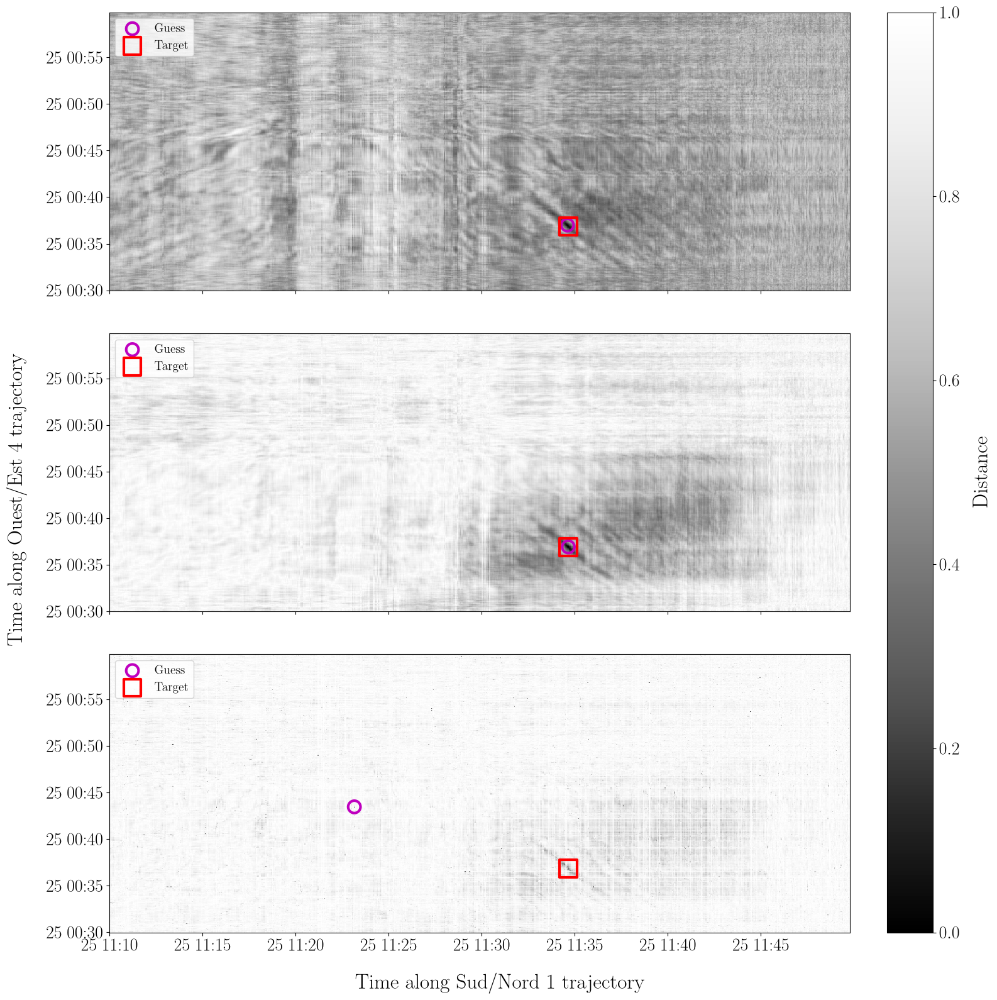

In [199]:
# vmin = max(np.nanmin(dist_theta_gamma), np.nanmin(dist_dcf))
# vmax = min(np.nanpercentile(dist_theta_gamma, 0.5), np.nanpercentile(dist_dcf, 0.5))

vmin = 0
vmax = 1

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 16), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta_gamma_norm.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    # vmin=np.nanmin(dist_theta_gamma),
    # vmax=np.nanpercentile(dist_theta_gamma, 0.5),
    vmin=vmin,
    vmax=vmax,
)
# plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma} (\in [0, 1])$")
im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_dcf_norm.T,
    cmap="Grays_r",
    # vmin=np.nanmin(dist_dcf),
    # vmax=np.nanpercentile(dist_dcf, 0.5),
    vmin=vmin,
    vmax=vmax,
)
# plt.colorbar(im, ax=axs[1], label=r"$DCF (\in [0, 1])$")

im = axs[2].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    dist_theta_norm.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta, 0.1),
    vmin=vmin,
    vmax=vmax,
)

axs[2].scatter(
    xmin_theta,
    ymin_theta,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

# Common colorbar
plt.colorbar(im, ax=axs, label="Distance")


axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin_dcf,
    ymin_dcf,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

for ax in axs.flatten():
    ax.scatter(
        xmin,
        ymin,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="r",
        label="Target",
        linewidth=3,
    )

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

Avec Pi on est plus précis et le contraste est supérieur. Néanmoins cela est au prix de la robustesse. De faible erreur d'estimation peuvent ainsi conduire à des lobes images ponctuelle. 

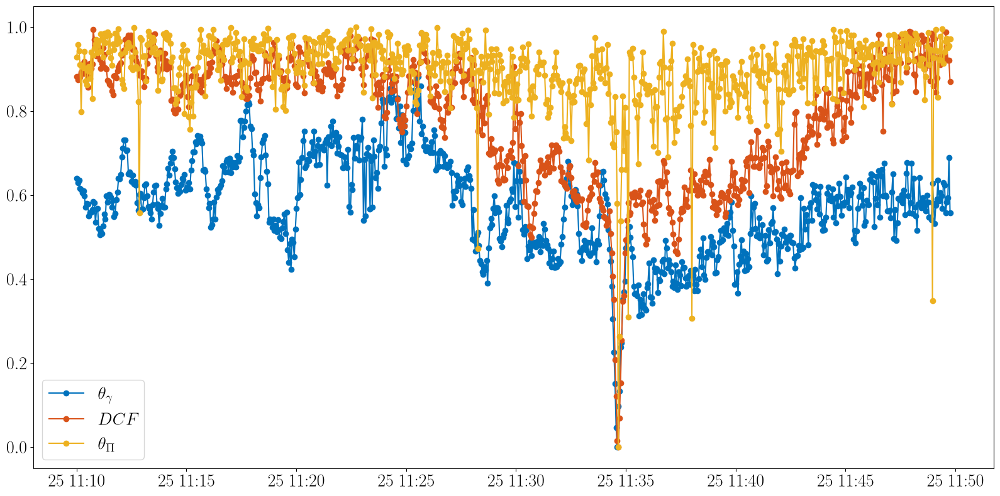

In [200]:
idx_ymin = np.abs(ds_feature_section2.src_datetime - ymin_theta_gamma).argmin(
    dim="src_datetime"
)
line_theta_gamma_norm = dist_theta_gamma_norm[:, idx_ymin]
idx_ymin = np.abs(ds_feature_section2.src_datetime - ymin_dcf).argmin(
    dim="src_datetime"
)
line_dcf_norm = dist_dcf_norm[:, idx_ymin]

line_theta = (line_theta - np.nanmin(line_theta)) / (np.nanmax(line_theta) - np.nanmin(line_theta))




plt.figure()
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta_gamma_norm,
    "-o",
    color=color(0),
    label=r"$\theta_{\gamma}$",
)
plt.plot(
    ds_feature_section1.src_datetime,
    line_dcf_norm,
    "-o",
    color=color(1),
    label=r"$DCF$",
)
plt.plot(
    ds_feature_section1.src_datetime,
    line_theta,
    "-o",
    color=color(2),
    label=r"$\theta_{\Pi}$",
)

plt.legend()

Ce n'est pas une bonne manière de comparer les deux résultats : dans le cas où l'un des deux OBS du couple est distant de l'OBS de référence theta croît avec la distance au point d'intersection et la normalisation dépend donc de la taille du domaine que l'on regarde. Plus le domaine est grand plus le contraste au point d'intersection va dimuner par normalisation.

### Combinaison des capteurs 

#### Somme des surfaces d'ambiguité 

In [201]:
def combine_rcv(rcv_ref="obs1", rcv_i_arr=["obs2"], fmin=5, fmax=50):
    ref_rcv_id = rcv_ref
    
    for i, rcv_id_i in enumerate(rcv_i_arr):

        pi_ij_a, gamma_a, sij_scot_a = derive_section_features(
            ds_feature_section=ds_feature_section1,
            fmin=fmin,
            fmax=fmax,
            rcv_ref=ref_rcv_id,
            rcv_i=rcv_id_i,
        )
        pi_ij_b, gamma_b, sij_scot_b = derive_section_features(
            ds_feature_section=ds_feature_section2,
            fmin=fmin,
            fmax=fmax,
            rcv_ref=ref_rcv_id,
            rcv_i=rcv_id_i,
        )

        features_section1 = dict(pi_ij=pi_ij_a, gamma_ij=gamma_a, sij_scot=sij_scot_a)
        features_section2 = dict(pi_ij=pi_ij_b, gamma_ij=gamma_b, sij_scot=sij_scot_b)

        dist_theta, dist_theta_gamma, dist_L2_gamma, dist_dcf = (
            derive_feature_distance_between_sections(features_section1, features_section2)
        )

        if i == 0:
            combined_dist_theta = dist_theta
            combined_dist_theta_gamma = dist_theta_gamma
            combined_dist_L2_gamma = dist_L2_gamma
            combined_dist_dcf = dist_dcf
        else:
            combined_dist_theta += dist_theta
            combined_dist_theta_gamma += dist_theta_gamma
            combined_dist_L2_gamma += dist_L2_gamma
            combined_dist_dcf += dist_dcf

    n_rcv_pairs = len(rcv_i_arr)
    combined_dist_theta = combined_dist_theta  / n_rcv_pairs
    combined_dist_theta_gamma = combined_dist_theta_gamma / n_rcv_pairs
    combined_dist_L2_gamma = combined_dist_L2_gamma / n_rcv_pairs
    combined_dist_dcf = combined_dist_dcf / n_rcv_pairs

    return combined_dist_theta, combined_dist_theta_gamma, combined_dist_L2_gamma, combined_dist_dcf


In [202]:
rcv_ref="obs1"
rcv_i_arr=["obs2", "obs4",  "obs7"]
fmin=5
fmax=50

combined_dist_theta, combined_dist_theta_gamma, combined_dist_L2_gamma, combined_dist_dcf = combine_rcv(rcv_ref="obs1", rcv_i_arr=["obs2"], fmin=5, fmax=50)

In [203]:
xmin, ymin = find_min_distance_position(dt1=ds_feature_section1.src_datetime, dt2=ds_feature_section2.src_datetime, dist=dist_12)

# Theta with pi
xmin_theta, ymin_theta = find_min_distance_position(
    dt1=ds_feature_section1.src_datetime,
    dt2=ds_feature_section2.src_datetime,
    dist=combined_dist_theta.T,
)

# Theta with gamma
xmin_theta_gamma, ymin_theta_gamma = find_min_distance_position(
    dt1=ds_feature_section1.src_datetime,
    dt2=ds_feature_section2.src_datetime,
    dist=combined_dist_theta_gamma.T,
)

# L2 with gamma
xmin_L2_gamma, ymin_L2_gamma = find_min_distance_position(
    dt1=ds_feature_section1.src_datetime,
    dt2=ds_feature_section2.src_datetime,
    dist=combined_dist_L2_gamma.T,
)

# DCF
xmin_dcf, ymin_dcf = find_min_distance_position(
    dt1=ds_feature_section1.src_datetime,
    dt2=ds_feature_section2.src_datetime,
    dist=combined_dist_dcf.T,
)

Text(0.02, 0.5, 'Time along Ouest/Est 4 trajectory')

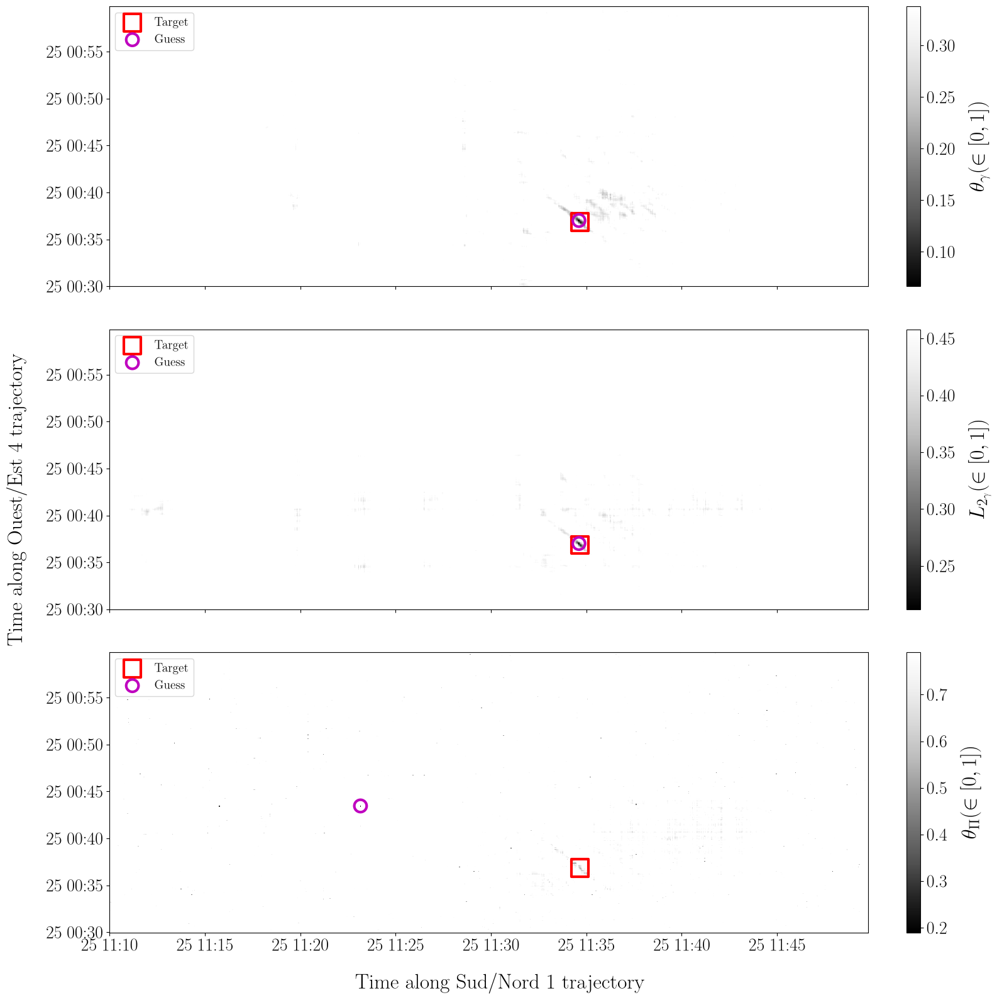

In [204]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 16), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    combined_dist_theta_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    vmin=np.nanmin(combined_dist_theta_gamma),
    vmax=np.nanpercentile(combined_dist_theta_gamma, 0.99),
)
plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma} (\in [0, 1])$")

im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    combined_dist_L2_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_L2_gamma, 0.1),
    vmin=np.nanmin(combined_dist_L2_gamma),
    vmax=np.nanpercentile(combined_dist_L2_gamma, 0.99),
)
plt.colorbar(im, ax=axs[1], label=r"$L_{2_{\gamma}} (\in [0, 1])$")

im = axs[2].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    combined_dist_theta.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta, 0.1),
    vmin=np.nanmin(combined_dist_theta),
    vmax=np.nanpercentile(combined_dist_theta, 0.99),
)
plt.colorbar(im, ax=axs[2], label=r"$\theta_{\Pi} (\in [0, 1])$")
axs[2].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[2].scatter(
    xmin_theta,
    ymin_theta,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[1].scatter(
    xmin_L2_gamma,
    ymin_L2_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

Text(0.02, 0.5, 'Time along Ouest/Est 4 trajectory')

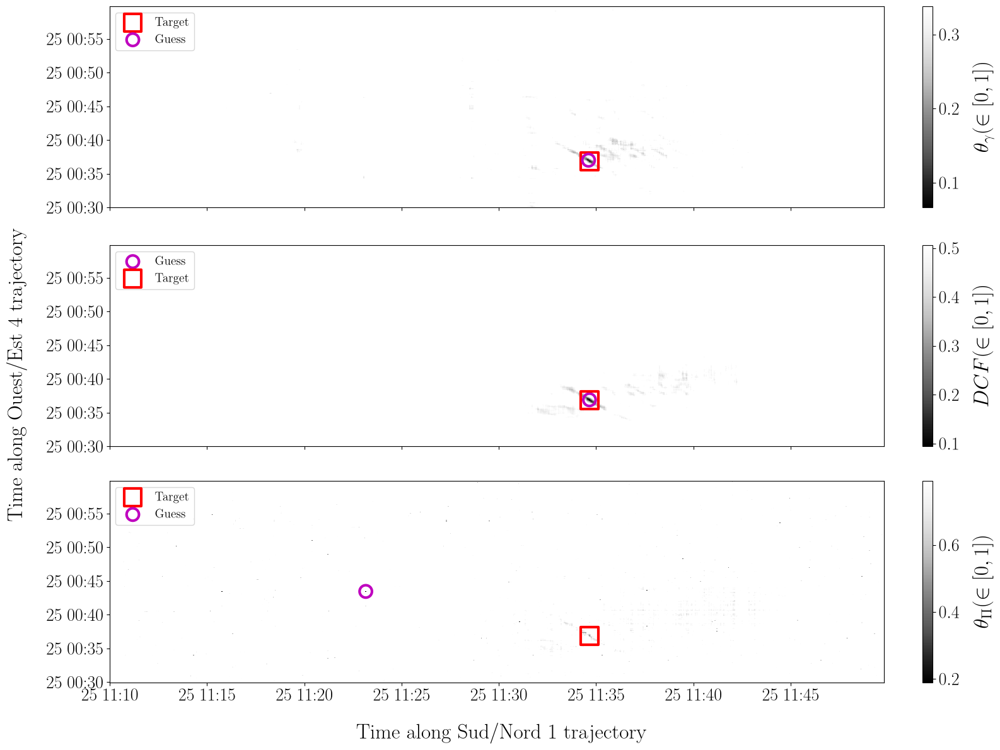

In [205]:
# vmin = max(np.nanmin(dist_theta_gamma), np.nanmin(dist_dcf))
# vmax = min(np.nanpercentile(dist_theta_gamma, 0.75), np.nanpercentile(dist_dcf, 0.75))


fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 12), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    combined_dist_theta_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    vmin=np.nanmin(combined_dist_theta_gamma),
    vmax=np.nanpercentile(combined_dist_theta_gamma, 0.99),
    # vmin=vmin,
    # vmax=vmax,
)
plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma} (\in [0, 1])$")
im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    combined_dist_dcf.T,
    cmap="Grays_r",
    vmin=np.nanmin(combined_dist_dcf),
    vmax=np.nanpercentile(combined_dist_dcf, 0.99),
    # vmin=vmin,
    # vmax=vmax,
)
plt.colorbar(im, ax=axs[1], label=r"$DCF (\in [0, 1])$")

im = axs[2].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    combined_dist_theta.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta, 0.1),
    vmin=np.nanmin(combined_dist_theta),
    vmax=np.nanpercentile(combined_dist_theta, 0.99),
)
plt.colorbar(im, ax=axs[2], label=r"$\theta_{\Pi} (\in [0, 1])$")
axs[2].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[2].scatter(
    xmin_theta,
    ymin_theta,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin_dcf,
    ymin_dcf,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

In [206]:
combined_dist_dcf_norm = (combined_dist_dcf - np.nanmin(combined_dist_dcf)) / (np.nanmax(combined_dist_dcf) - np.nanmin(combined_dist_dcf))
combined_dist_theta_gamma_norm = (combined_dist_theta_gamma - np.nanmin(combined_dist_theta_gamma)) / (np.nanmax(combined_dist_theta_gamma) - np.nanmin(combined_dist_theta_gamma))
combined_dist_theta_norm = (combined_dist_theta- np.nanmin(combined_dist_theta)) / (np.nanmax(combined_dist_theta) - np.nanmin(combined_dist_theta))

Text(0.02, 0.5, 'Time along Ouest/Est 4 trajectory')

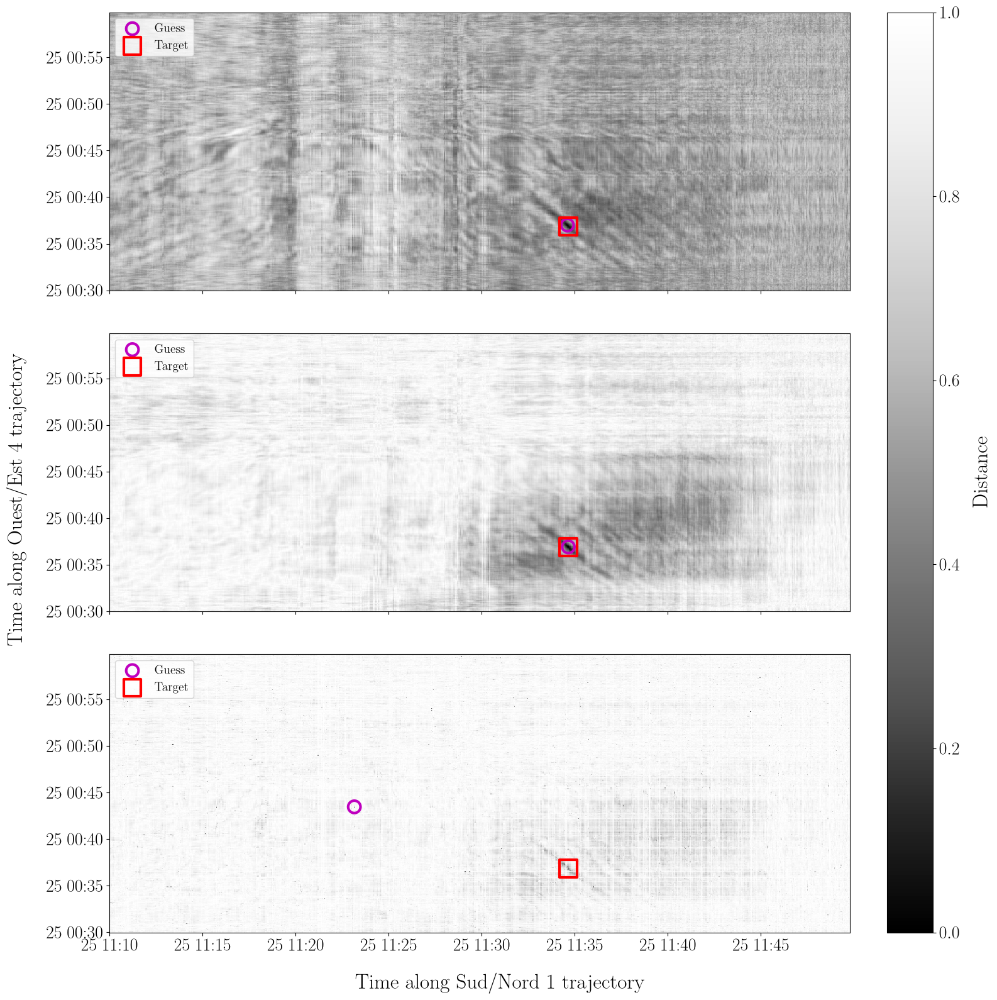

In [207]:
# vmin = max(np.nanmin(dist_theta_gamma), np.nanmin(dist_dcf))
# vmax = min(np.nanpercentile(dist_theta_gamma, 0.5), np.nanpercentile(dist_dcf, 0.5))

vmin = 0
vmax = 1

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 16), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    combined_dist_theta_gamma_norm.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    # vmin=np.nanmin(dist_theta_gamma),
    # vmax=np.nanpercentile(dist_theta_gamma, 0.5),
    vmin=vmin,
    vmax=vmax,
)
# plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma} (\in [0, 1])$")
im = axs[1].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    combined_dist_dcf_norm.T,
    cmap="Grays_r",
    # vmin=np.nanmin(dist_dcf),
    # vmax=np.nanpercentile(dist_dcf, 0.5),
    vmin=vmin,
    vmax=vmax,
)
# plt.colorbar(im, ax=axs[1], label=r"$DCF (\in [0, 1])$")

im = axs[2].pcolormesh(
    ds_feature_section1.src_datetime,
    ds_feature_section2.src_datetime,
    combined_dist_theta_norm.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta, 0.1),
    vmin=vmin,
    vmax=vmax,
)

axs[2].scatter(
    xmin_theta,
    ymin_theta,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

# Common colorbar
plt.colorbar(im, ax=axs, label="Distance")


axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin_dcf,
    ymin_dcf,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

for ax in axs.flatten():
    ax.scatter(
        xmin,
        ymin,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="r",
        label="Target",
        linewidth=3,
    )

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)